In [1]:
#needed imports
from collections import OrderedDict
import copy
import logging
import os
import urllib.request
import zipfile
import glob 

from astropy.time import Time
import astropy.units as u
from IPython.display import display, Markdown
from gaiasupdate.epoch_astrometry import GaiaEpochAstrometryArchive
from astropy.table import Table
import numpy as np
import periapsis as p
import matplotlib.pyplot as plt
import pandas as pd

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


# Fitting Gaia BH3 with DR4 Prerelease 
>First, we need to grab the data. Data retrieval coutersy of https://github.com/esa/gaia-bhthree/blob/gaia-dr4-prerelease/Gaia-DR4-prerelease_BH3_fit_astrometric_orbit.ipynb

In [2]:
url = "https://anonftp.cosmos.esa.int/pub/GAIA_PUBLIC_DATA/Gaia_DR4/dr4-prerelease/gaia-dr4-prerelease-epoch-astrometry_2026-06-26.zip"

local_dir = os.getcwd()

download_path = os.path.join(local_dir, 'downloaded_file.zip')
extract_path = os.path.join(local_dir, 'extracted_files')

if not os.path.isfile(download_path):

    # Download the file
    urllib.request.urlretrieve(url, os.path.basename(download_path))
   

with zipfile.ZipFile(download_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)



epoch_astrometry_file = glob.glob(os.path.join(extract_path, '*.xml'))[0]


table = Table.read(epoch_astrometry_file, format="votable")
epoch_astrometry = table.to_pandas()


In [3]:
name_dict = {'Gaia BH3': 4318465066420528000,
    'HD 114762': 3937211745905473024,
    'Gaia-4': 1457486023639239296}


source_id = name_dict['Gaia BH3'] # for Gaia BH3
# source_id = name_dict['HD 114762'] 
# source_id = name_dict['Gaia-4'] 

m1_MS = 0.76  # Primary star mass for Gaia BH3
target_ra_deg = 294.8278502411 # Right Ascension for Gaia BH3
target_dec_deg = 14.9309190720 # Declination for Gaia BH3


epoch_astrometry_bh3 = epoch_astrometry[epoch_astrometry['source_id'] == source_id]

In [4]:
ea = GaiaEpochAstrometryArchive.from_dataframe(epoch_astrometry_bh3)

# use only data used by the Gaia DR4 core astrometric solution
ea.epoch_data = ea.epoch_data.epochastrometryarchive.filter_on_used_by_agis()

# sort by increasing time
ea.epoch_data.epochastrometryarchive.sort_by_column('obs_time_tcb')

# set auxiliary fields
ea.epoch_data.epochastrometryarchive.set_relative_time() # sets 'relative_time_year','relative_time_day'
ea.epoch_data = ea.epoch_data.epochastrometryarchive.set_scan_angle_derived_columns() # sets 'sin_theta', 'cos_theta', 'sin_theta_time', 'cos_theta_time
ea.epoch_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 558 entries, 0 to 557
Data columns (total 42 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   solution_id                558 non-null    int64  
 1   source_id                  558 non-null    int64  
 2   transit_id                 558 non-null    int64  
 3   ra0                        558 non-null    float64
 4   dec0                       558 non-null    float64
 5   agis_source_excess_noise   558 non-null    float32
 6   obs_time_tcb               558 non-null    int64  
 7   obs_time_bary_corr         558 non-null    float32
 8   scan_pos_angle             558 non-null    float64
 9   zeta                       558 non-null    float32
 10  parallax_factor_al         558 non-null    float32
 11  parallax_factor_ac         558 non-null    float32
 12  colour_factor_al           558 non-null    float64
 13  colour_factor_ac           558 non-null    object 

/uufs/astro.utah.edu/common/home/u1383373/software/pkg/miniforge3/lib/python3.12/site-packages/pandas/core/dtypes/astype.py:133: UserWarning: Warning: converting a masked element to nan.
  return arr.astype(dtype, copy=True)
/uufs/astro.utah.edu/common/home/u1383373/software/pkg/miniforge3/lib/python3.12/site-packages/pandas/core/dtypes/astype.py:133: UserWarning: Warning: converting a masked element to nan.
  return arr.astype(dtype, copy=True)
/uufs/astro.utah.edu/common/home/u1383373/software/pkg/miniforge3/lib/python3.12/site-packages/pandas/core/dtypes/astype.py:133: UserWarning: Warning: converting a masked element to nan.
  return arr.astype(dtype, copy=True)
/uufs/astro.utah.edu/common/home/u1383373/software/pkg/miniforge3/lib/python3.12/site-packages/pandas/core/dtypes/astype.py:133: UserWarning: Warning: converting a masked element to nan.
  return arr.astype(dtype, copy=True)


 Grab Data needed for fit

In [5]:
gaia_astrometry = ea.epoch_data.copy()

spsi = gaia_astrometry['sin_theta'].values
cpsi = gaia_astrometry['cos_theta'].values
ti = gaia_astrometry['relative_time_year'].values
plx_factor = gaia_astrometry['parallax_factor_al'].values
x = gaia_astrometry['centroid_pos_al'].values
err = gaia_astrometry['centroid_pos_error_al'].values

We need to now set up the data object and priors for fitting

In [6]:
# Set up units and initialize GaiaData object
units = {'t':'year', 'x':'mas', 'err':'mas'}
data = p.GaiaData(spsi,cpsi,ti,plx_factor,x,err,units=units,system='1')

# Set up priors for the model parameters
# Prior units must correspond to data object with same dimensionality

priors_lin = {
    'P': p.UniformPrior(0.1,50), # Period, years
    'e': p.UniformPrior(0.0, 0.95), # Eccentricity
    't0': p.UniformPrior(-0.5,0.5), # Tp/P, dimensionless
    'astro_jitter': p.LogUniformPrior(0.001,0.5), # Jitter, mas
    'M1': p.FixedPrior(m1_MS)
}

Set up the Fitter

In [7]:
fitter1 = p.MCMCLinearFitter(
    nwalkers=80,
    niter=10000,
    sampled_params = ['P', 'e', 't0', 'astro_jitter'],
    **priors_lin
)
results1 = fitter1.fit(data,rng=np.random.default_rng(42))

ASSUMPTION: Assuming prior on 'P' is in units of yr. To suppress this warning, explicitly set the unit on the prior.
ASSUMPTION: Assuming prior on 'astro_jitter' is in units of mas. To suppress this warning, explicitly set the unit on the prior.
ASSUMPTION: Assuming prior on 'M1' is in units of solMass. To suppress this warning, explicitly set the unit on the prior.
ASSUMPTION: Assuming prior on 'Tepoch' is in units of yr. To suppress this warning, explicitly set the unit on the prior.


100%|██████████| 10000/10000 [05:22<00:00, 31.00it/s]


Check results and fit statistics

In [8]:
stats1,fit_results1 = p.all_stats(results1,data)

{
    "red_chi2_map": 1.0351571363070362,
    "red_chi2_med": 1.0228637371579727,
    "dof": 545,
    "uwe_map": 1.0174267228194058,
    "uwe_med": 1.011367261264657,
    "delta_chi2_map": 3678390.812308728,
    "delta_chi2_med": 3678397.5122112646,
    "p_value_map": 0.0,
    "p_value_med": 0.0,
    "sigma_significance": 110606.74793836393,
    "sampled_params": [
        "P",
        "e",
        "t0",
        "astro_jitter"
    ],
    "Ess": [
        16925.063205943337,
        16977.087586303696,
        16763.401688628543,
        24699.348632175923
    ],
    "mean_acceptance_fraction": 0.5905925,
    "tau": [
        47.26717946430328,
        47.122334495429115,
        47.723010810072054,
        32.38951811700157
    ]
}


{
    "MAP_params": {
        "P": 11.535262513855852,
        "e": 0.7294471684966128,
        "t0": 0.057429656591067135,
        "astro_jitter": 5.532608630034781e-10,
        "dalpha_ang": 1.654401646671515e-08,
        "mu_alpha_ang": -1.3730787252847

Generate visualizations for orbit and fit properties

/uufs/astro.utah.edu/common/home/u1383373/software/pkg/miniforge3/lib/python3.12/site-packages/matplotlib/axes/_axes.py:7096: RuntimeWarning: All-NaN slice encountered
  xmin = min(xmin, np.nanmin(xi))
/uufs/astro.utah.edu/common/home/u1383373/software/pkg/miniforge3/lib/python3.12/site-packages/matplotlib/axes/_axes.py:7097: RuntimeWarning: All-NaN slice encountered
  xmax = max(xmax, np.nanmax(xi))
/uufs/astro.utah.edu/common/home/u1383373/software/pkg/miniforge3/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:901: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


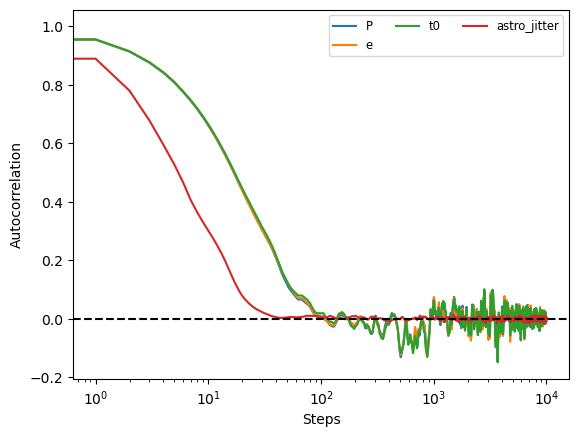

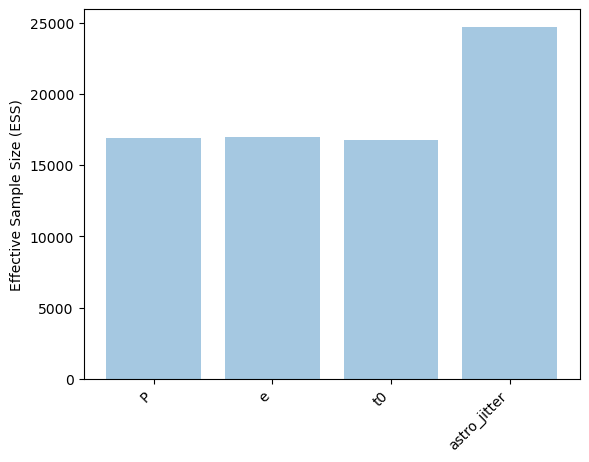

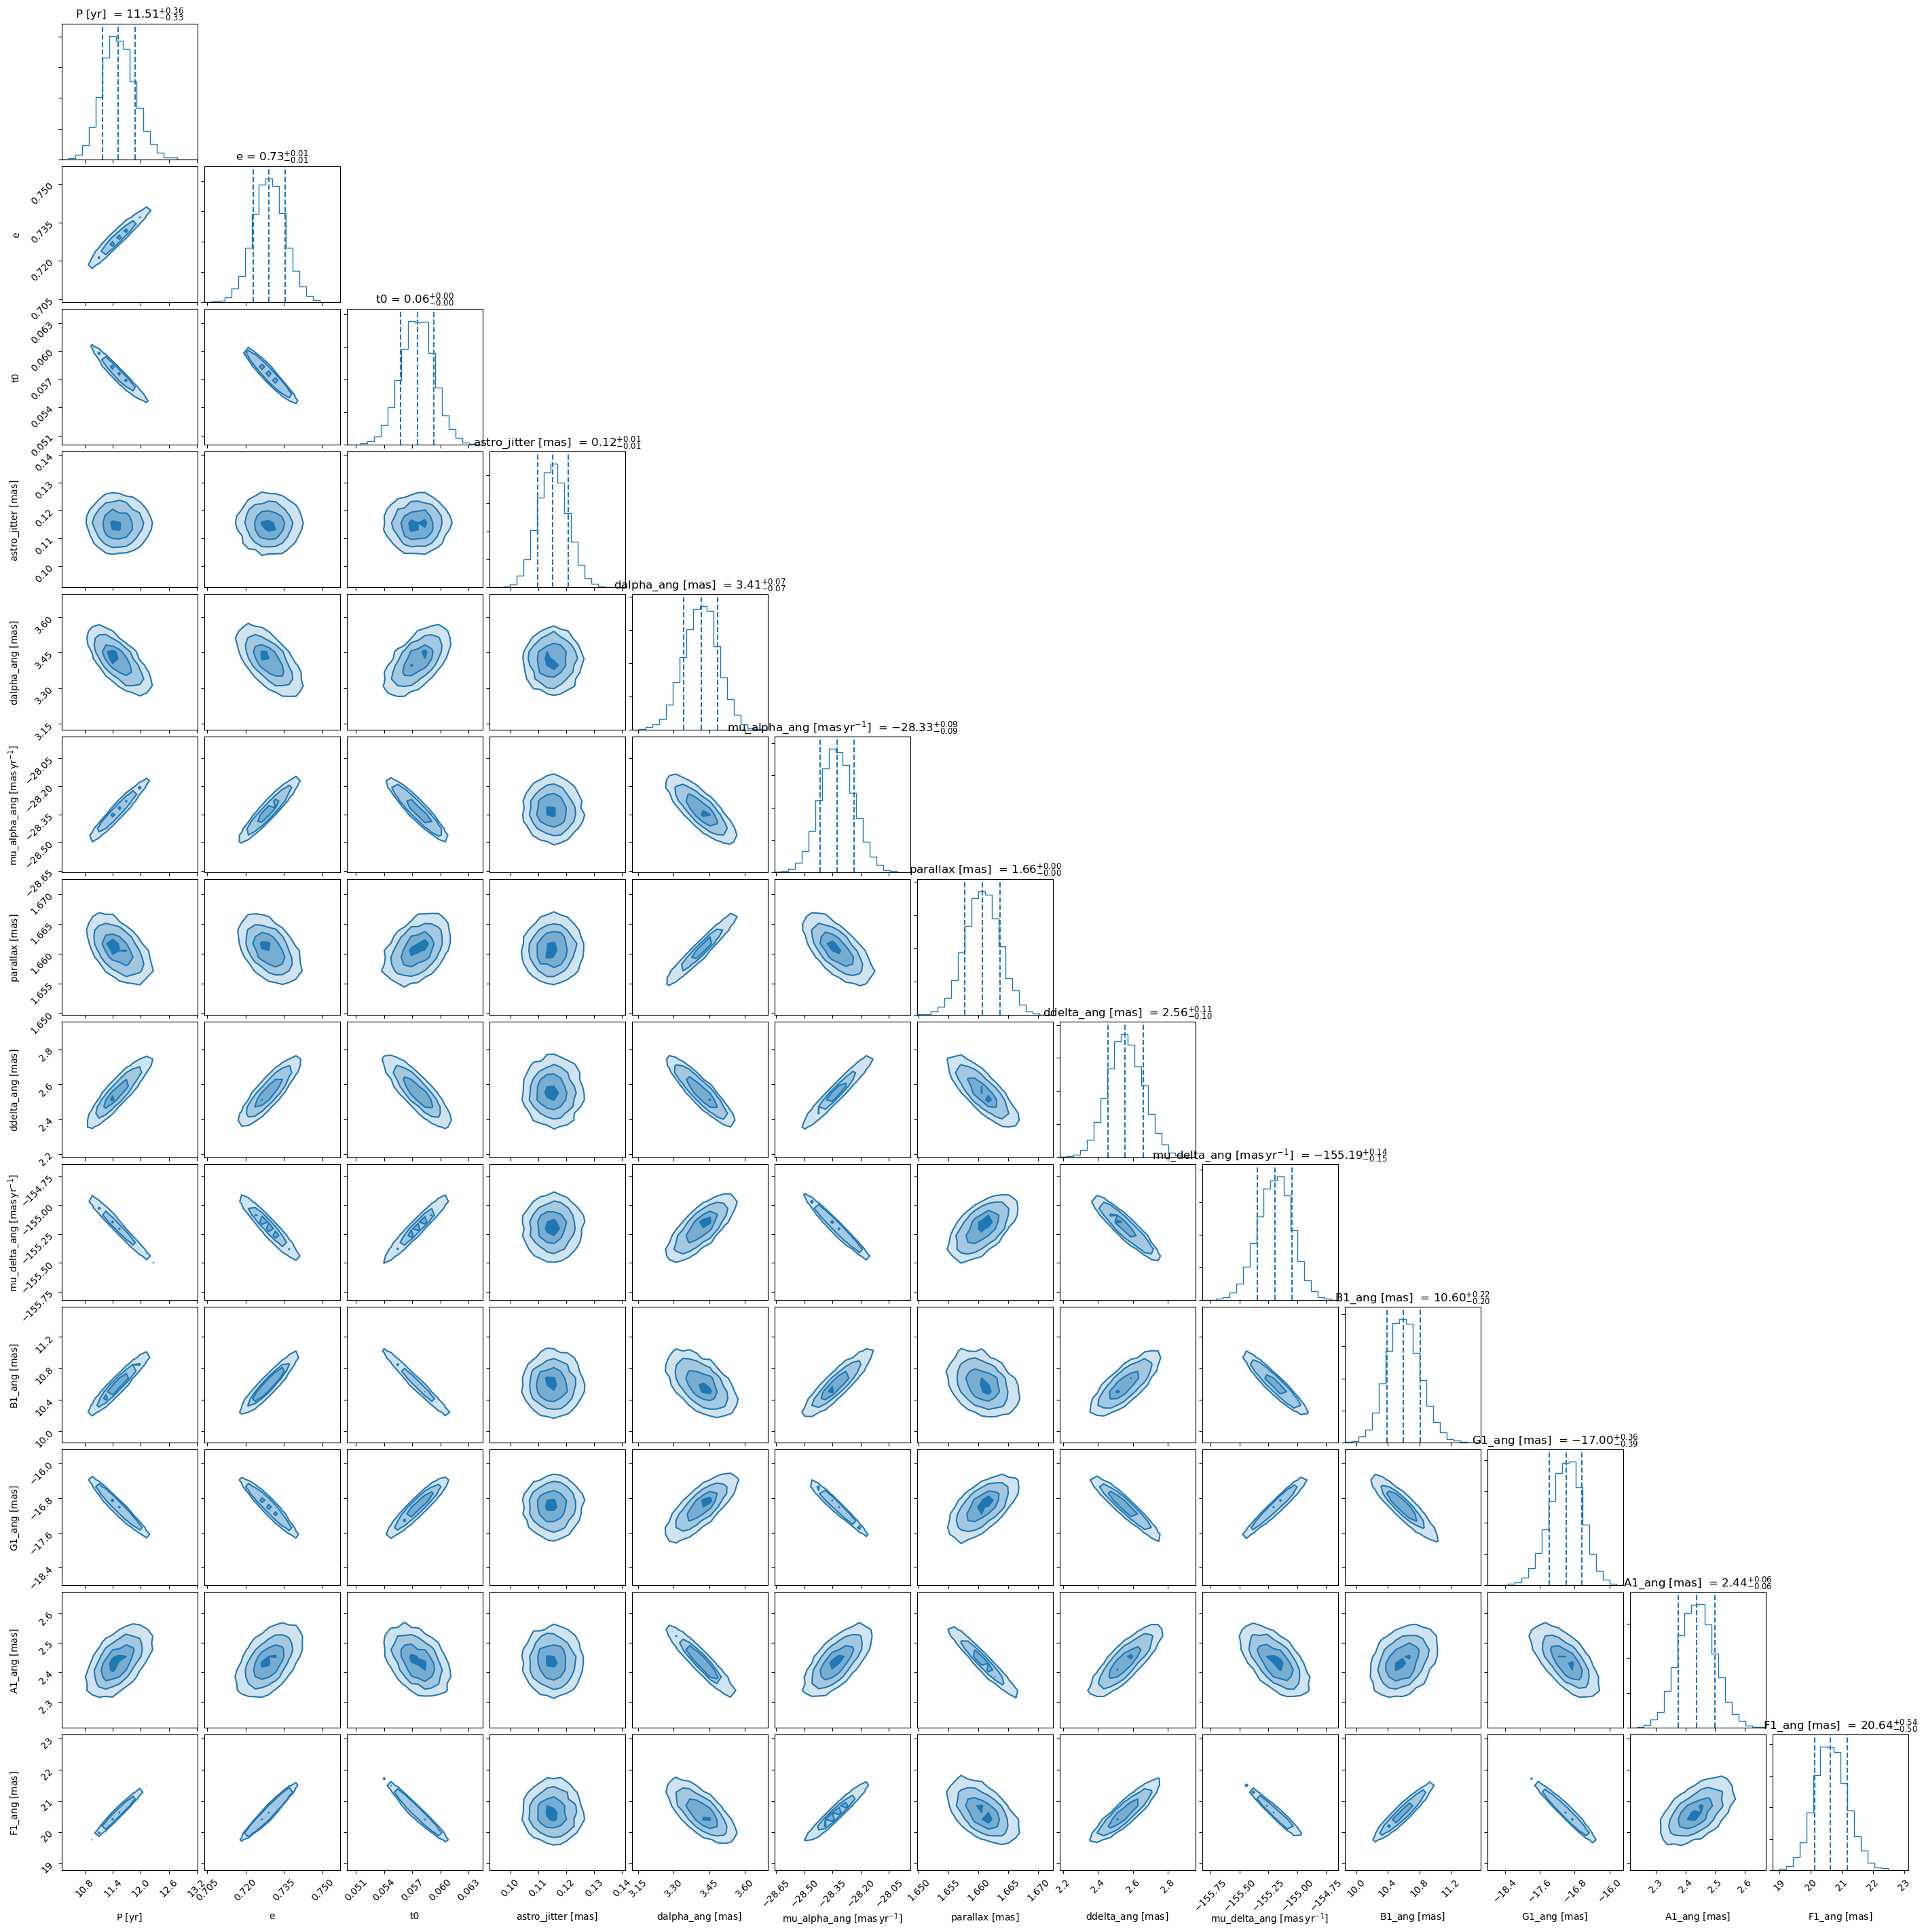

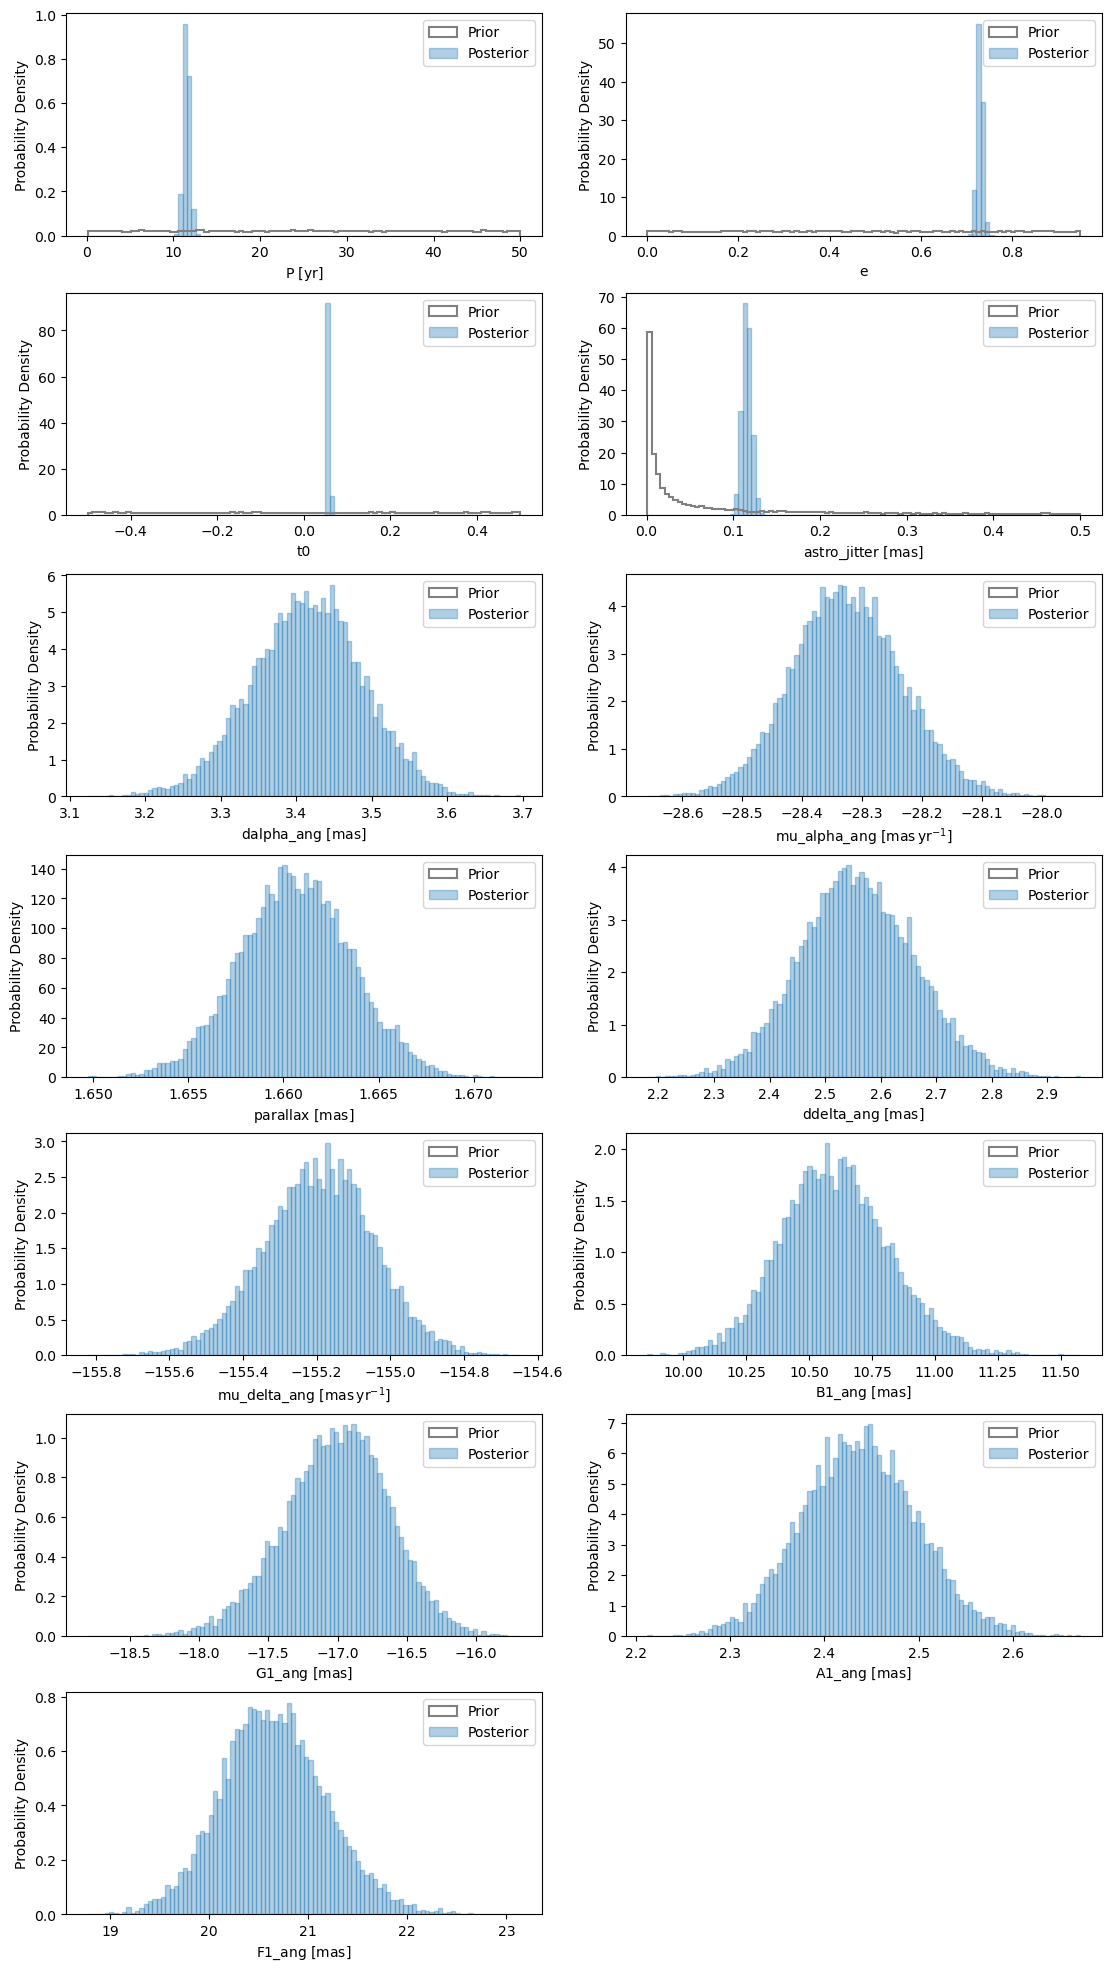

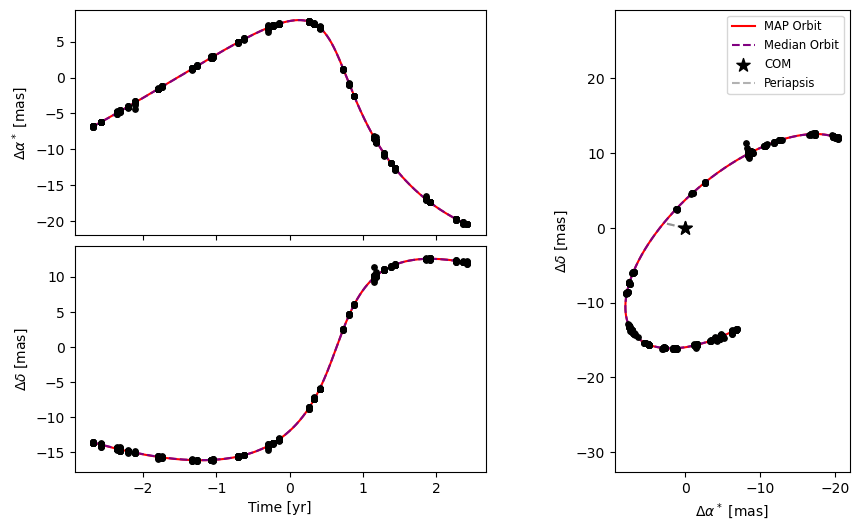

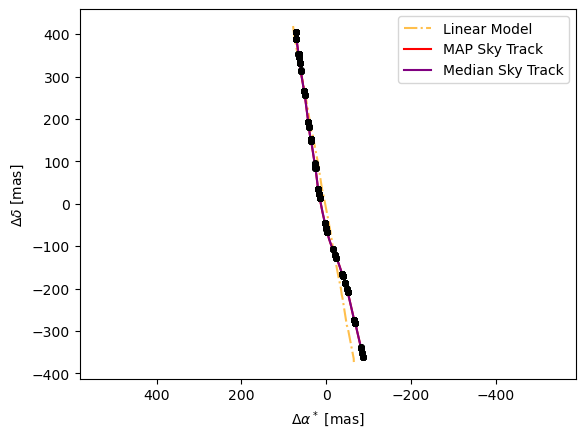

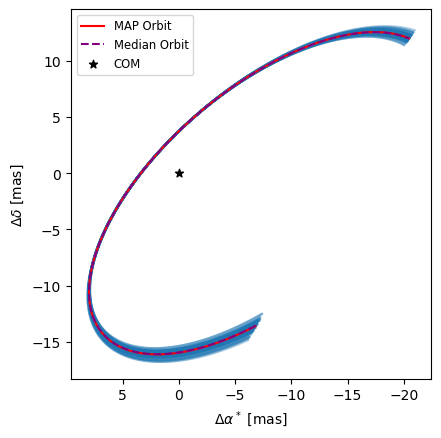

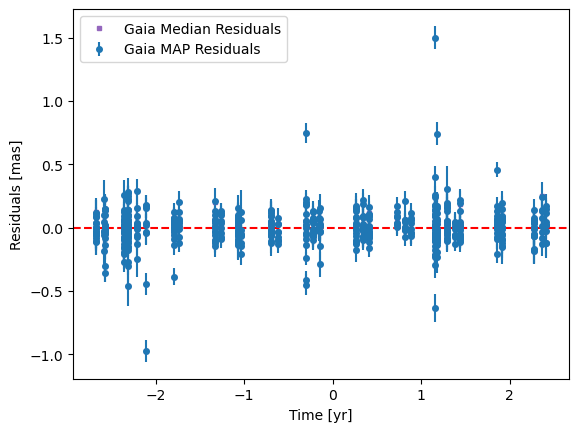

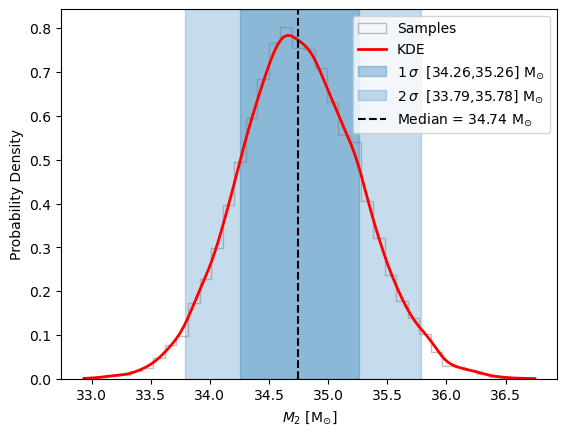

In [9]:
p.all_plots(results1,data)

# RV Joint Fit

In [10]:
df = pd.read_csv('data/gaiabh3/gaiabh3_rv.tsv', comment='#', sep=r'\s+', 
                 names=['TransitID', 'ObsTime', 'RV', 'e_RV'], skiprows=37)


In [11]:
DR4_REF_JD = 2457936.375 #2017.5

# Convert raw RV Julian Dates into relative years from 2017.5
df['relative_time_year'] = (df['ObsTime'] - DR4_REF_JD) / 365.25


In [12]:
rv_t = df['relative_time_year'].values
rv = df['RV'].values
rv_err = df['e_RV'].values

units_rv = {'t':'year', 'rv':'km/s', 'rv_err':'km/s'}

rv_data = p.RadialVelocityData(rv_t, rv, rv_err, units=units_rv, system='1')

Now we can initialize the JointData

In [13]:
datasets = [data, rv_data]
joint = p.JointData(datasets)

In [14]:
#Linear fit using same priors as before

fitter_joint = p.MCMCLinearFitter(
    nwalkers=60,
    niter=10000,
    sampled_params = ['P', 'e', 't0', 'astro_jitter'],
    **priors_lin
)

results_joint = fitter_joint.fit(joint,rng=np.random.default_rng(42))

ASSUMPTION: Assuming prior on 'Tepoch' is in units of yr. To suppress this warning, explicitly set the unit on the prior.


100%|██████████| 10000/10000 [05:00<00:00, 33.32it/s]


In [15]:
results_joint

### Fit Results (linear emcee on JointData)

$\chi^2_{\rm red., med} = 1.024899$, $\chi^2_{\rm red., MAP} = 1.031771$

(559 degrees of freedom)

#### Parameters and Uncertainties

| Parameter | Median (1-$\sigma$) | MAP | Unit |
| :--- | :--- | :--- | :--- |
| $P$ (sampled) | $11.58^{+0.34}_{-0.31}$ | $11.61$ | $\mathrm{yr}$ |
| $e$ (sampled) | $0.730^{+0.006}_{-0.006}$ | $0.731$ | $\mathrm{}$ |
| $t_0$ (sampled) | $0.0572^{+0.0016}_{-0.0017}$ | $0.0570$ | $\mathrm{}$ |
| $astro_jitter$ (sampled) | $0.115^{+0.005}_{-0.005}$ | $0.115$ | $\mathrm{mas}$ |
| $T_\mathrm{epoch}$ | $0.0$ | $0.0$ | $\mathrm{yr}$ |
| ${M}_{1}$ | $0.76$ | $0.76$ | $\mathrm{M_{\odot}}$ |
| $T_p$ | $0.6624^{+0.0030}_{-0.0029}$ | ${\rm N/A}$ | $\mathrm{yr}$ |
| ${\Delta \alpha}_{\mathrm{ang}}$ | $3.41^{+0.07}_{-0.07}$ | $3.40$ | $\mathrm{mas}$ |
| ${\mu_\alpha}_{\mathrm{ang}}$ | $-28.31^{+0.09}_{-0.08}$ | $-28.30$ | $\mathrm{mas\,yr^{-1}}$ |
| $\mathrm{parallax}$ | $1.6604^{+0.0028}_{-0.0029}$ | $1.6603$ | $\mathrm{mas}$ |
| ${\Delta \delta}_{\mathrm{ang}}$ | $2.57^{+0.10}_{-0.09}$ | $2.58$ | $\mathrm{mas}$ |
| ${\mu_\delta}_{\mathrm{ang}}$ | $-155.22^{+0.13}_{-0.14}$ | $-155.24$ | $\mathrm{mas\,yr^{-1}}$ |
| ${{B}_{1}}_{\mathrm{ang}}$ | $10.64^{+0.21}_{-0.20}$ | $10.66$ | $\mathrm{mas}$ |
| ${{G}_{1}}_{\mathrm{ang}}$ | $-17.06^{+0.34}_{-0.36}$ | $-17.10$ | $\mathrm{mas}$ |
| ${{A}_{1}}_{\mathrm{ang}}$ | $2.44^{+0.06}_{-0.06}$ | $2.44$ | $\mathrm{mas}$ |
| ${{F}_{1}}_{\mathrm{ang}}$ | $20.7^{+0.5}_{-0.5}$ | $20.8$ | $\mathrm{mas}$ |
| $\gamma$ | $-357.18^{+0.28}_{-0.29}$ | $-357.21$ | $\mathrm{km\,s^{-1}}$ |
| ${h}_{1}$ | $12.0^{+0.4}_{-0.4}$ | $12.1$ | $\mathrm{km\,s^{-1}}$ |
| ${c}_{1}$ | $-55.39^{+0.19}_{-0.19}$ | $-55.37$ | $\mathrm{km\,s^{-1}}$ |

#### Other Available Parameters
Other available parameters (access with `fit_results['param_name']`): $A$, ${A}_{1}$, ${A}_{2}$, ${{A}_{2}}_{\mathrm{ang}}$, ${A}_{\mathrm{ang}}$, $B$, ${B}_{1}$, ${B}_{2}$, ${{B}_{2}}_{\mathrm{ang}}$, ${B}_{\mathrm{ang}}$, $C$, ${C}_{1}$, ${C}_{2}$, $E_0$, $F$, ${F}_{1}$, ${F}_{2}$, ${{F}_{2}}_{\mathrm{ang}}$, ${F}_{\mathrm{ang}}$, $G$, ${G}_{1}$, ${G}_{2}$, ${{G}_{2}}_{\mathrm{ang}}$, ${G}_{\mathrm{ang}}$, $H$, ${H}_{1}$, ${H}_{2}$, $K$, ${K}_{1}$, ${K}_{2}$, $L_0$, $M_0$, $M_1 \sin i$, ${M}_{2}$, $M_2 \sin i$, $M\sin i$, $M_\mathrm{tot}$, $\Omega$, ${\Omega}_{1}$, ${\Omega}_{2}$, $a$, ${a}_{1}$, ${{a}_{1}}_{\mathrm{ang}}$, $a_1 \sin i$, ${a}_{2}$, ${{a}_{2}}_{\mathrm{ang}}$, $a_2 \sin i$, ${a}_{\mathrm{ang}}$, $b$, ${b}_{1}$, ${{b}_{1}}_{\mathrm{ang}}$, ${b}_{2}$, ${{b}_{2}}_{\mathrm{ang}}$, ${b}_{\mathrm{ang}}$, $c$, ${c}_{2}$, $\cos i$, $\Delta \alpha$, $\Delta \delta$, $\mathrm{distance}$, ${f}_{1}$, ${f}_{2}$, $h$, ${h}_{2}$, $i$, $l_0$, ${l_0}_{1}$, ${l_0}_{2}$, ${\min M}_{1}$, ${\min M}_{2}$, $\mu$, $\mu_\alpha$, $\mu_\delta$, $n$, $\nu_0$, $\omega$, ${\omega}_{1}$, ${\omega}_{2}$, $p$, ${p}_{1}$, ${{p}_{1}}_{\mathrm{ang}}$, ${p}_{2}$, ${{p}_{2}}_{\mathrm{ang}}$, ${p}_{\mathrm{ang}}$, $\varpi$, ${\varpi}_{1}$, ${\varpi}_{2}$, $q$, $r_a$, ${r_a}_{1}$, ${{r_a}_{1}}_{\mathrm{ang}}$, ${r_a}_{2}$, ${{r_a}_{2}}_{\mathrm{ang}}$, ${r_a}_{\mathrm{ang}}$, $r_p$, ${r_p}_{1}$, ${{r_p}_{1}}_{\mathrm{ang}}$, ${r_p}_{2}$, ${{r_p}_{2}}_{\mathrm{ang}}$, ${r_p}_{\mathrm{ang}}$, $\sin i$, $u_0$, ${u_0}_{1}$, ${u_0}_{2}$, $u_{M_0}$, ${u_{M_0}}_{1}$, ${u_{M_0}}_{2}$

/uufs/astro.utah.edu/common/home/u1383373/software/pkg/miniforge3/lib/python3.12/site-packages/matplotlib/axes/_axes.py:7096: RuntimeWarning: All-NaN slice encountered
  xmin = min(xmin, np.nanmin(xi))
/uufs/astro.utah.edu/common/home/u1383373/software/pkg/miniforge3/lib/python3.12/site-packages/matplotlib/axes/_axes.py:7097: RuntimeWarning: All-NaN slice encountered
  xmax = max(xmax, np.nanmax(xi))
/uufs/astro.utah.edu/common/home/u1383373/software/pkg/miniforge3/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:901: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


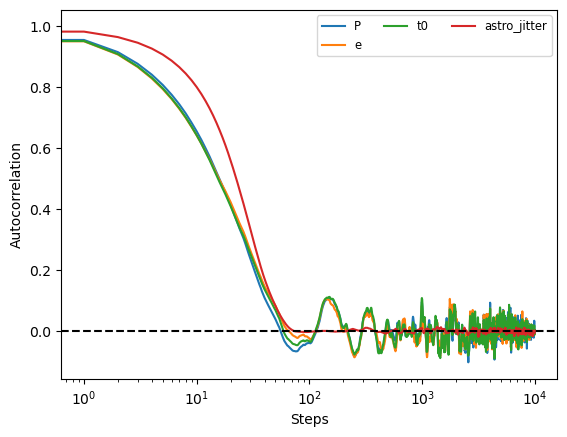

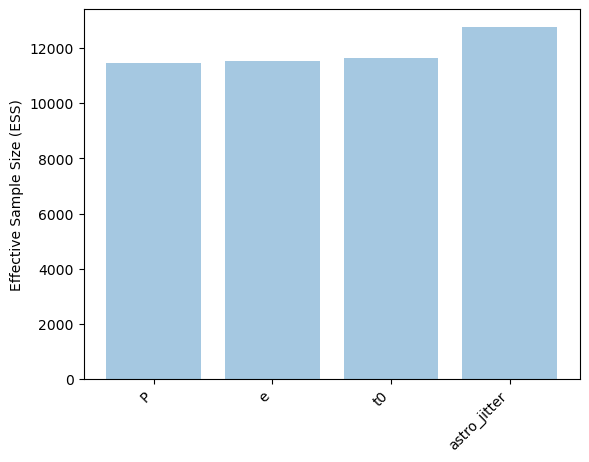

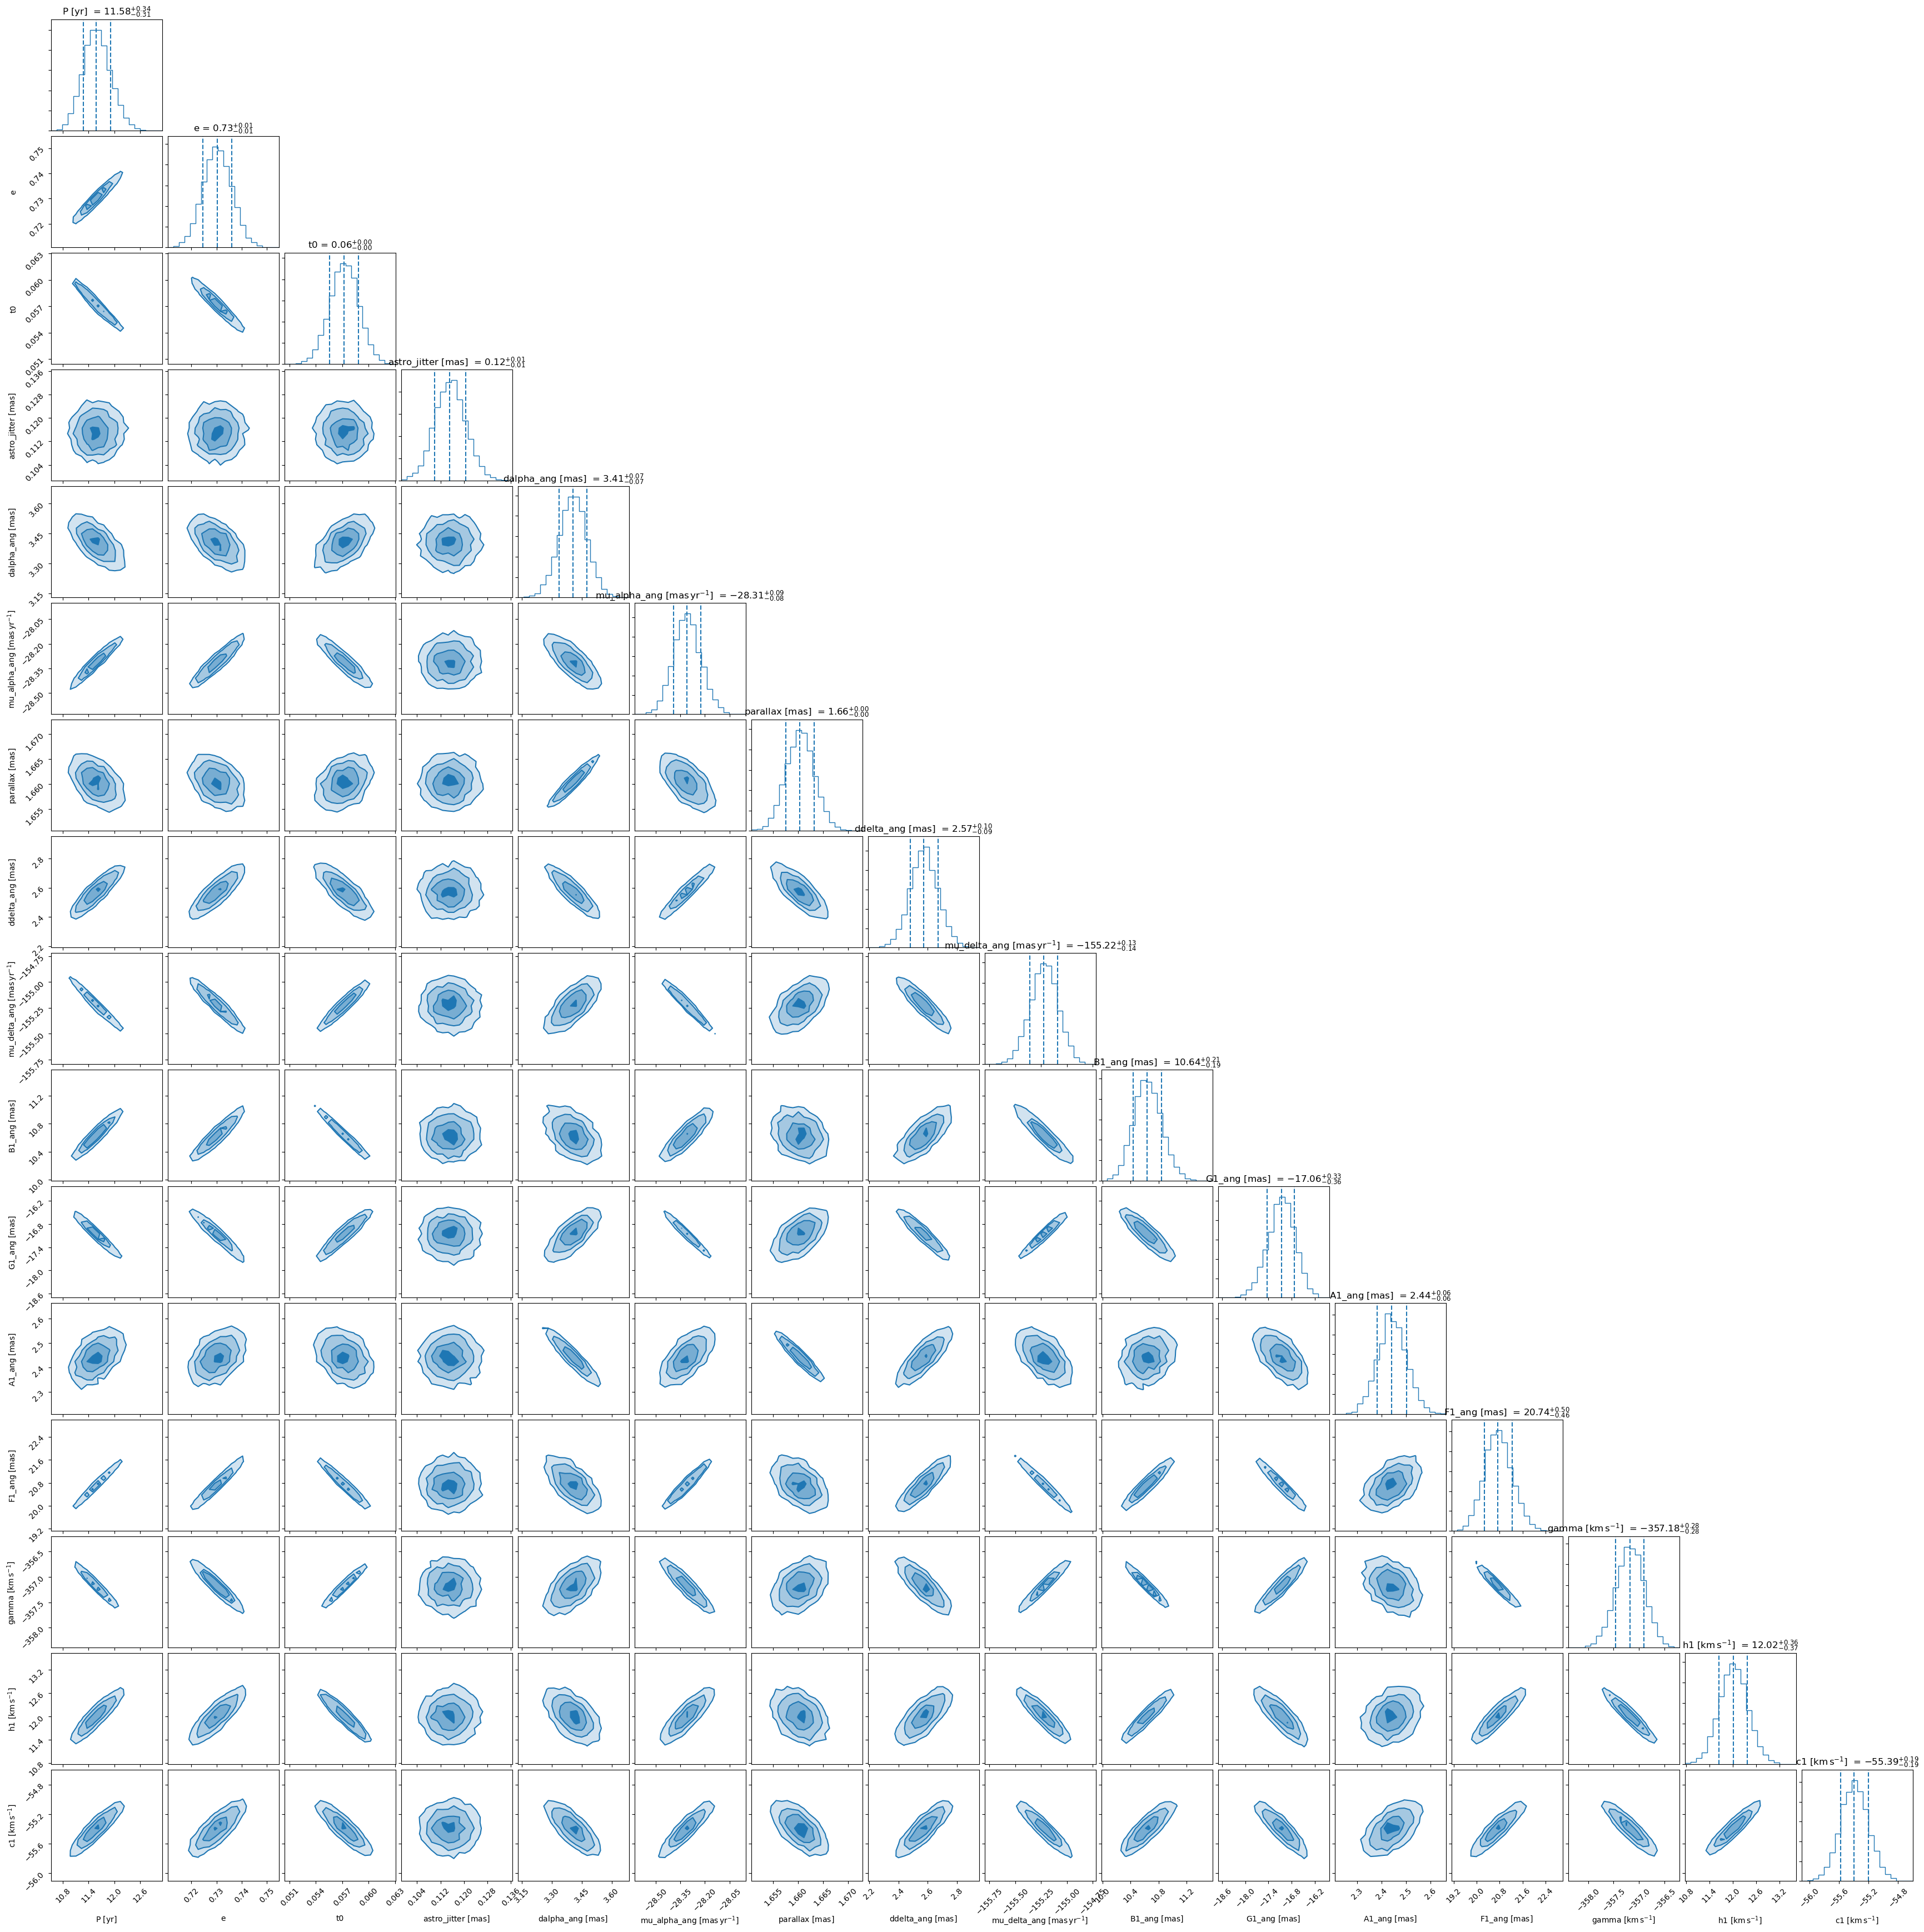

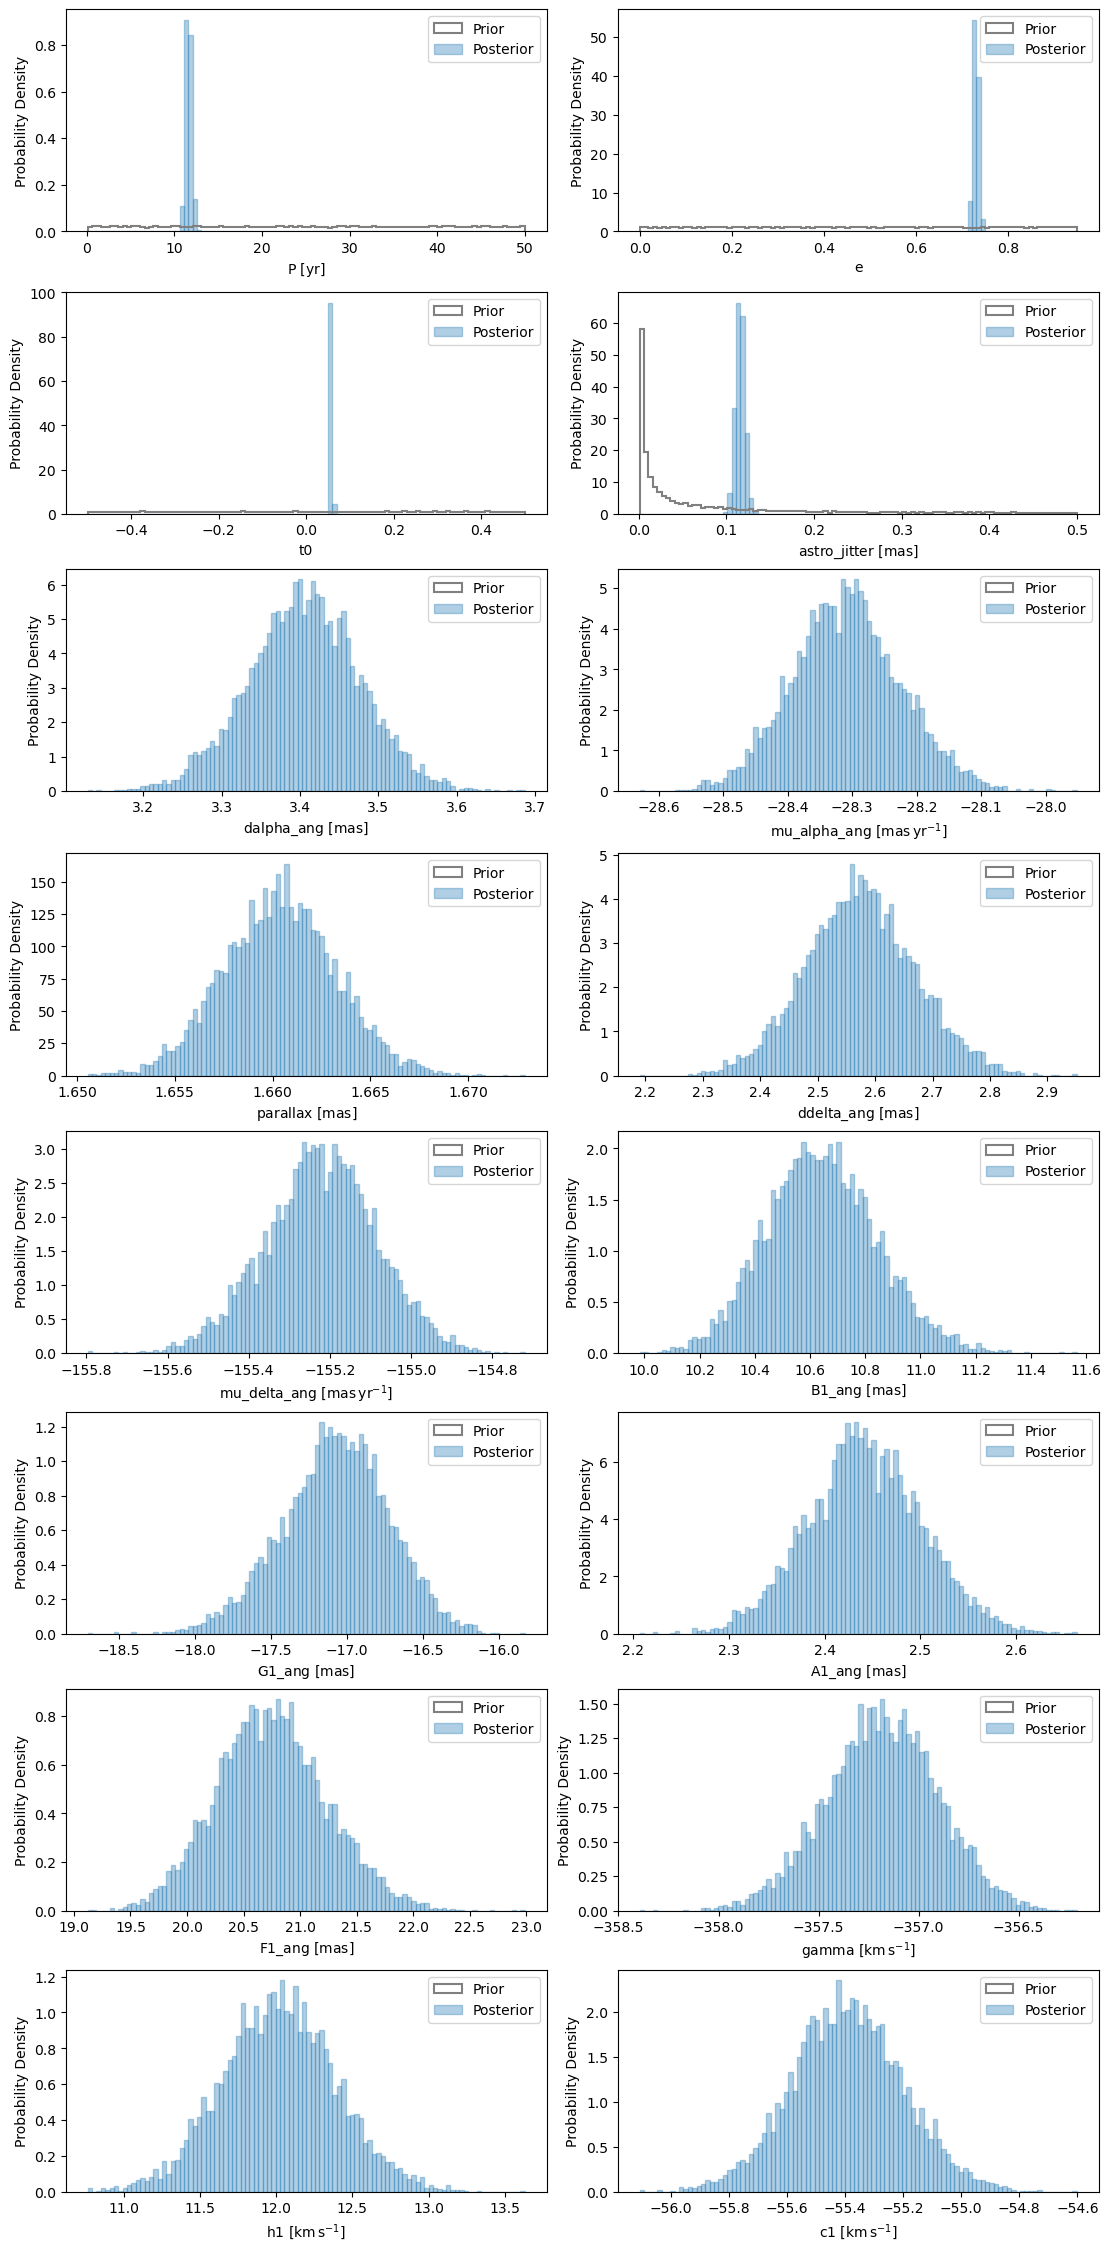

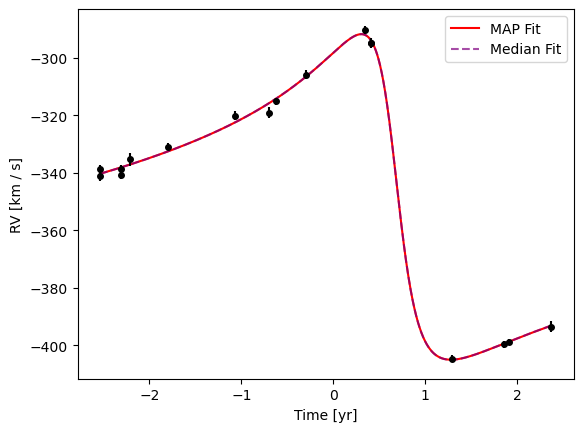

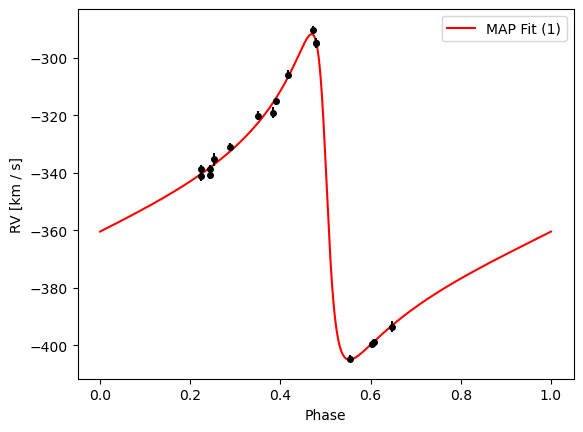

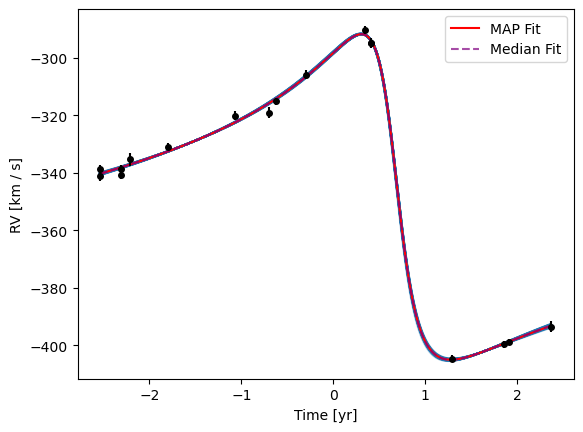

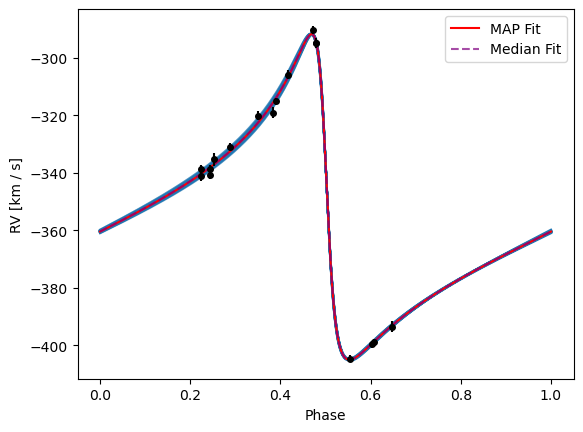

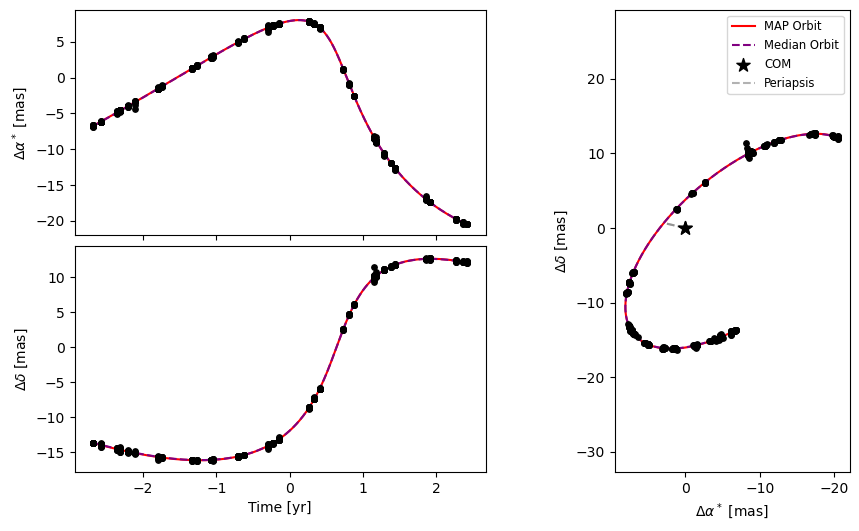

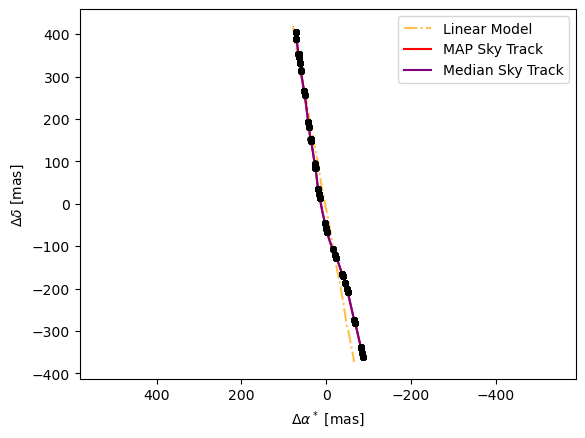

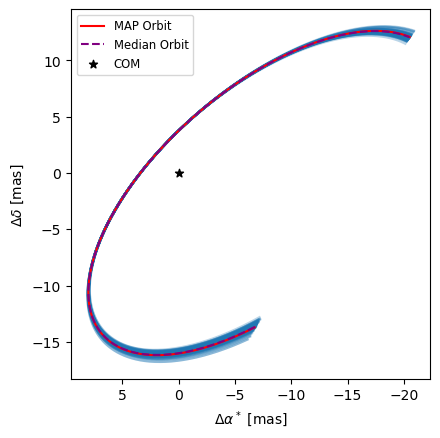

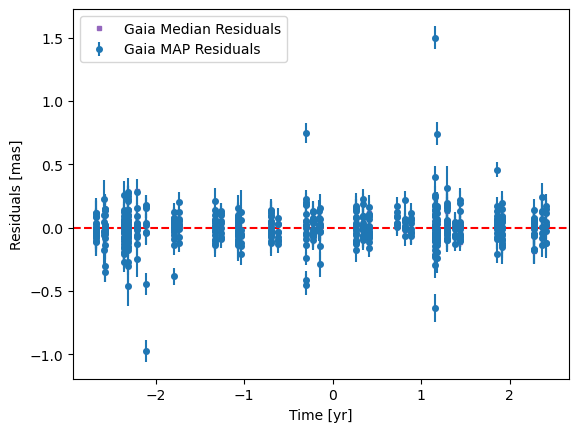

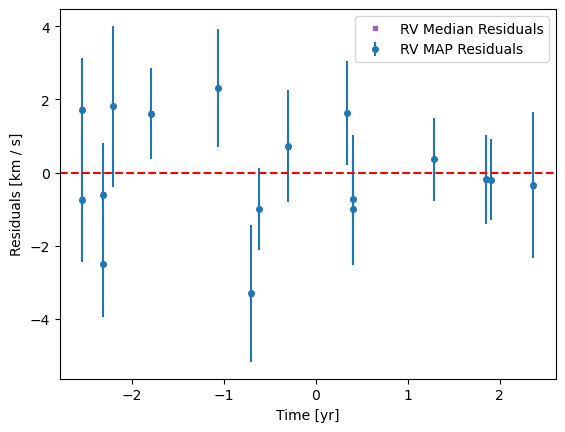

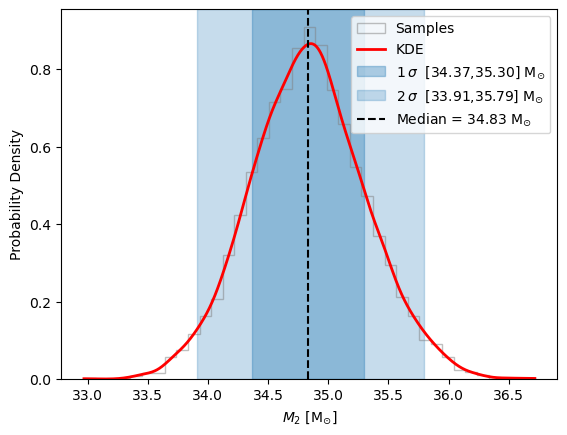

In [16]:
p.all_plots(results_joint,joint)

> Lets try to fit the full parameter vector

In [17]:
full_priors = {
    'P' : p.UniformPrior(1,30),
    'e': p.UniformPrior(0,0.95),
    't0': p.UniformPrior(-0.5,0.5),
    'a1_ang': p.UniformPrior(0,30,unit='mas'),
    'cosi' : p.UniformPrior(-1,1),
    'omega1' : p.UniformPrior(0,2*np.pi),
    'Omega1' : p.UniformPrior(0,2*np.pi),
    'K1' : p.UniformPrior(0,100,unit='km/s'),
    'gamma': p.UniformPrior(-400,-200,unit='km/s'),
    'dalpha_ang': p.UniformPrior(-10,10,unit='mas'),
    'ddelta_ang': p.UniformPrior(-10,10,unit='mas'),
    'mu_alpha_ang': p.UniformPrior(-200,200,unit='mas/yr'),
    'mu_delta_ang': p.UniformPrior(-200,200,unit='mas/yr'),
    'parallax': p.UniformPrior(0.01,50,unit='mas'),
    'astro_jitter': p.LogUniformPrior(0.001,0.5,unit='mas'),
    'M1': p.FixedPrior(m1_MS)
}

In [18]:
full_param_fit = p.MCMCFitter(
    nwalkers = 80,
    niter = 50000,
    sample_params = ['P', 'e', 't0', 'a1_ang','cosi','omega1','Omega1','K1',
    'gamma', 'dalpha_ang', 'ddelta_ang', 'mu_alpha_ang', 'mu_delta_ang', 'parallax', 'astro_jitter'],
    **full_priors
)

In [19]:

results_full = full_param_fit.fit(joint,rng=np.random.default_rng(42))

ASSUMPTION: Assuming prior on 'P' is in units of yr. To suppress this warning, explicitly set the unit on the prior.
ASSUMPTION: Assuming prior on 'omega1' is in units of rad. To suppress this warning, explicitly set the unit on the prior.
ASSUMPTION: Assuming prior on 'Omega1' is in units of rad. To suppress this warning, explicitly set the unit on the prior.
ASSUMPTION: Assuming prior on 'M1' is in units of solMass. To suppress this warning, explicitly set the unit on the prior.
ASSUMPTION: Assuming prior on 'Tepoch' is in units of yr. To suppress this warning, explicitly set the unit on the prior.


100%|██████████| 50000/50000 [35:20<00:00, 23.58it/s]


In [20]:
results_full 

### Fit Results (full emcee on JointData)

$\chi^2_{\rm red., med} = 1.008735$, $\chi^2_{\rm red., MAP} = 1.048614$

(560 degrees of freedom)

#### Parameters and Uncertainties

| Parameter | Median (1-$\sigma$) | MAP | Unit |
| :--- | :--- | :--- | :--- |
| $P$ (sampled) | $11.50^{+0.29}_{-0.27}$ | $11.51$ | $\mathrm{yr}$ |
| $e$ (sampled) | $0.729^{+0.005}_{-0.005}$ | $0.729$ | $\mathrm{}$ |
| $t_0$ (sampled) | $0.0576^{+0.0015}_{-0.0015}$ | $0.0575$ | $\mathrm{}$ |
| ${{a}_{1}}_{\mathrm{ang}}$ (sampled) | $27.2^{+0.5}_{-0.5}$ | $27.2$ | $\mathrm{mas}$ |
| $\cos i$ (sampled) | $-0.3507^{+0.0019}_{-0.0019}$ | $-0.3507$ | $\mathrm{}$ |
| ${\omega}_{1}$ (sampled) | $1.3653^{+0.0032}_{-0.0033}$ | $1.3652$ | $\mathrm{rad}$ |
| ${\Omega}_{1}$ (sampled) | $5.5213^{+0.0025}_{-0.0025}$ | $5.5215$ | $\mathrm{rad}$ |
| ${K}_{1}$ (sampled) | $56.7^{+0.5}_{-0.5}$ | $57.1$ | $\mathrm{km\,s^{-1}}$ |
| $\gamma$ (sampled) | $-357.1^{+0.4}_{-0.4}$ | $-357.4$ | $\mathrm{km\,s^{-1}}$ |
| ${\Delta \alpha}_{\mathrm{ang}}$ (sampled) | $3.42^{+0.07}_{-0.07}$ | $3.43$ | $\mathrm{mas}$ |
| ${\Delta \delta}_{\mathrm{ang}}$ (sampled) | $2.55^{+0.09}_{-0.09}$ | $2.55$ | $\mathrm{mas}$ |
| ${\mu_\alpha}_{\mathrm{ang}}$ (sampled) | $-28.33^{+0.08}_{-0.08}$ | $-28.33$ | $\mathrm{mas\,yr^{-1}}$ |
| ${\mu_\delta}_{\mathrm{ang}}$ (sampled) | $-155.19^{+0.12}_{-0.12}$ | $-155.19$ | $\mathrm{mas\,yr^{-1}}$ |
| $\mathrm{parallax}$ (sampled) | $1.661^{+0.012}_{-0.012}$ | $1.667$ | $\mathrm{mas}$ |
| $astro_jitter$ (sampled) | $0.117^{+0.005}_{-0.005}$ | $0.113$ | $\mathrm{mas}$ |
| $T_\mathrm{epoch}$ | $0.0$ | $0.0$ | $\mathrm{yr}$ |
| ${M}_{1}$ | $0.76$ | $0.76$ | $\mathrm{M_{\odot}}$ |

#### Other Available Parameters
Other available parameters (access with `fit_results['param_name']`): $A$, ${A}_{1}$, ${{A}_{1}}_{\mathrm{ang}}$, ${A}_{2}$, ${{A}_{2}}_{\mathrm{ang}}$, ${A}_{\mathrm{ang}}$, $B$, ${B}_{1}$, ${{B}_{1}}_{\mathrm{ang}}$, ${B}_{2}$, ${{B}_{2}}_{\mathrm{ang}}$, ${B}_{\mathrm{ang}}$, $C$, ${C}_{1}$, ${C}_{2}$, $E_0$, $F$, ${F}_{1}$, ${{F}_{1}}_{\mathrm{ang}}$, ${F}_{2}$, ${{F}_{2}}_{\mathrm{ang}}$, ${F}_{\mathrm{ang}}$, $G$, ${G}_{1}$, ${{G}_{1}}_{\mathrm{ang}}$, ${G}_{2}$, ${{G}_{2}}_{\mathrm{ang}}$, ${G}_{\mathrm{ang}}$, $H$, ${H}_{1}$, ${H}_{2}$, $K$, ${K}_{2}$, $L_0$, $M_0$, $M_1 \sin i$, ${M}_{2}$, $M_2 \sin i$, $M\sin i$, $M_\mathrm{tot}$, $\Omega$, ${\Omega}_{2}$, $T_p$, $a$, ${a}_{1}$, $a_1 \sin i$, ${a}_{2}$, ${{a}_{2}}_{\mathrm{ang}}$, $a_2 \sin i$, ${a}_{\mathrm{ang}}$, $b$, ${b}_{1}$, ${{b}_{1}}_{\mathrm{ang}}$, ${b}_{2}$, ${{b}_{2}}_{\mathrm{ang}}$, ${b}_{\mathrm{ang}}$, $c$, ${c}_{1}$, ${c}_{2}$, $\Delta \alpha$, $\Delta \delta$, $\mathrm{distance}$, ${f}_{1}$, ${f}_{2}$, $h$, ${h}_{1}$, ${h}_{2}$, $i$, $l_0$, ${l_0}_{1}$, ${l_0}_{2}$, ${\min M}_{1}$, ${\min M}_{2}$, $\mu$, $\mu_\alpha$, $\mu_\delta$, $n$, $\nu_0$, $\omega$, ${\omega}_{2}$, $p$, ${p}_{1}$, ${{p}_{1}}_{\mathrm{ang}}$, ${p}_{2}$, ${{p}_{2}}_{\mathrm{ang}}$, ${p}_{\mathrm{ang}}$, $\varpi$, ${\varpi}_{1}$, ${\varpi}_{2}$, $q$, $r_a$, ${r_a}_{1}$, ${{r_a}_{1}}_{\mathrm{ang}}$, ${r_a}_{2}$, ${{r_a}_{2}}_{\mathrm{ang}}$, ${r_a}_{\mathrm{ang}}$, $r_p$, ${r_p}_{1}$, ${{r_p}_{1}}_{\mathrm{ang}}$, ${r_p}_{2}$, ${{r_p}_{2}}_{\mathrm{ang}}$, ${r_p}_{\mathrm{ang}}$, $\sin i$, $u_0$, ${u_0}_{1}$, ${u_0}_{2}$, $u_{M_0}$, ${u_{M_0}}_{1}$, ${u_{M_0}}_{2}$

In [21]:
results_full['M2']

${M}_{2}$ Posterior Samples (n=18000):
`[34.68849355 35.72598499 35.07166435 ... 34.35704495 34.46737158
 35.52730141]` $\mathrm{M_{\odot}}$


Median = 34.70976593488821 $\mathrm{M_{\odot}}$

MAP    = 34.39426979168244 $\mathrm{M_{\odot}}$

1-sigma confidence interval: $34.7^{+0.9}_{-0.8}$ $\mathrm{M_{\odot}}$

2-sigma confidence interval: $34.7^{+1.7}_{-1.6}$ $\mathrm{M_{\odot}}$

3-sigma confidence interval: $34.7^{+2.6}_{-2.4}$ $\mathrm{M_{\odot}}$

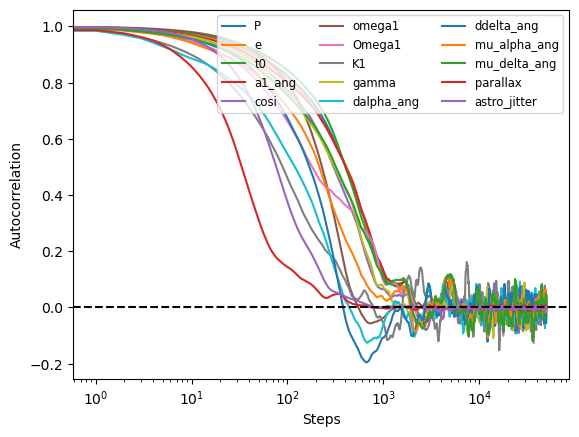

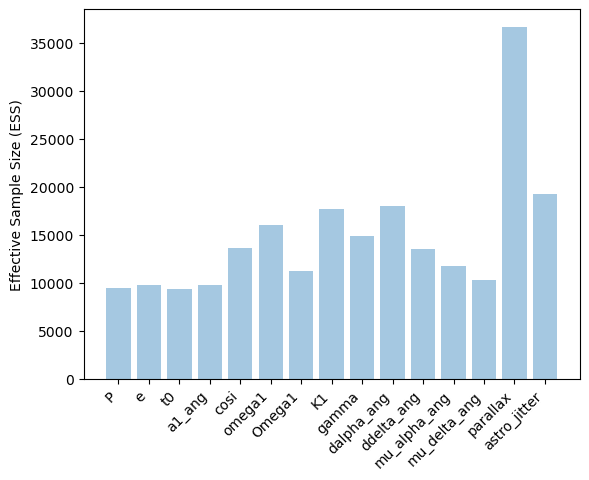

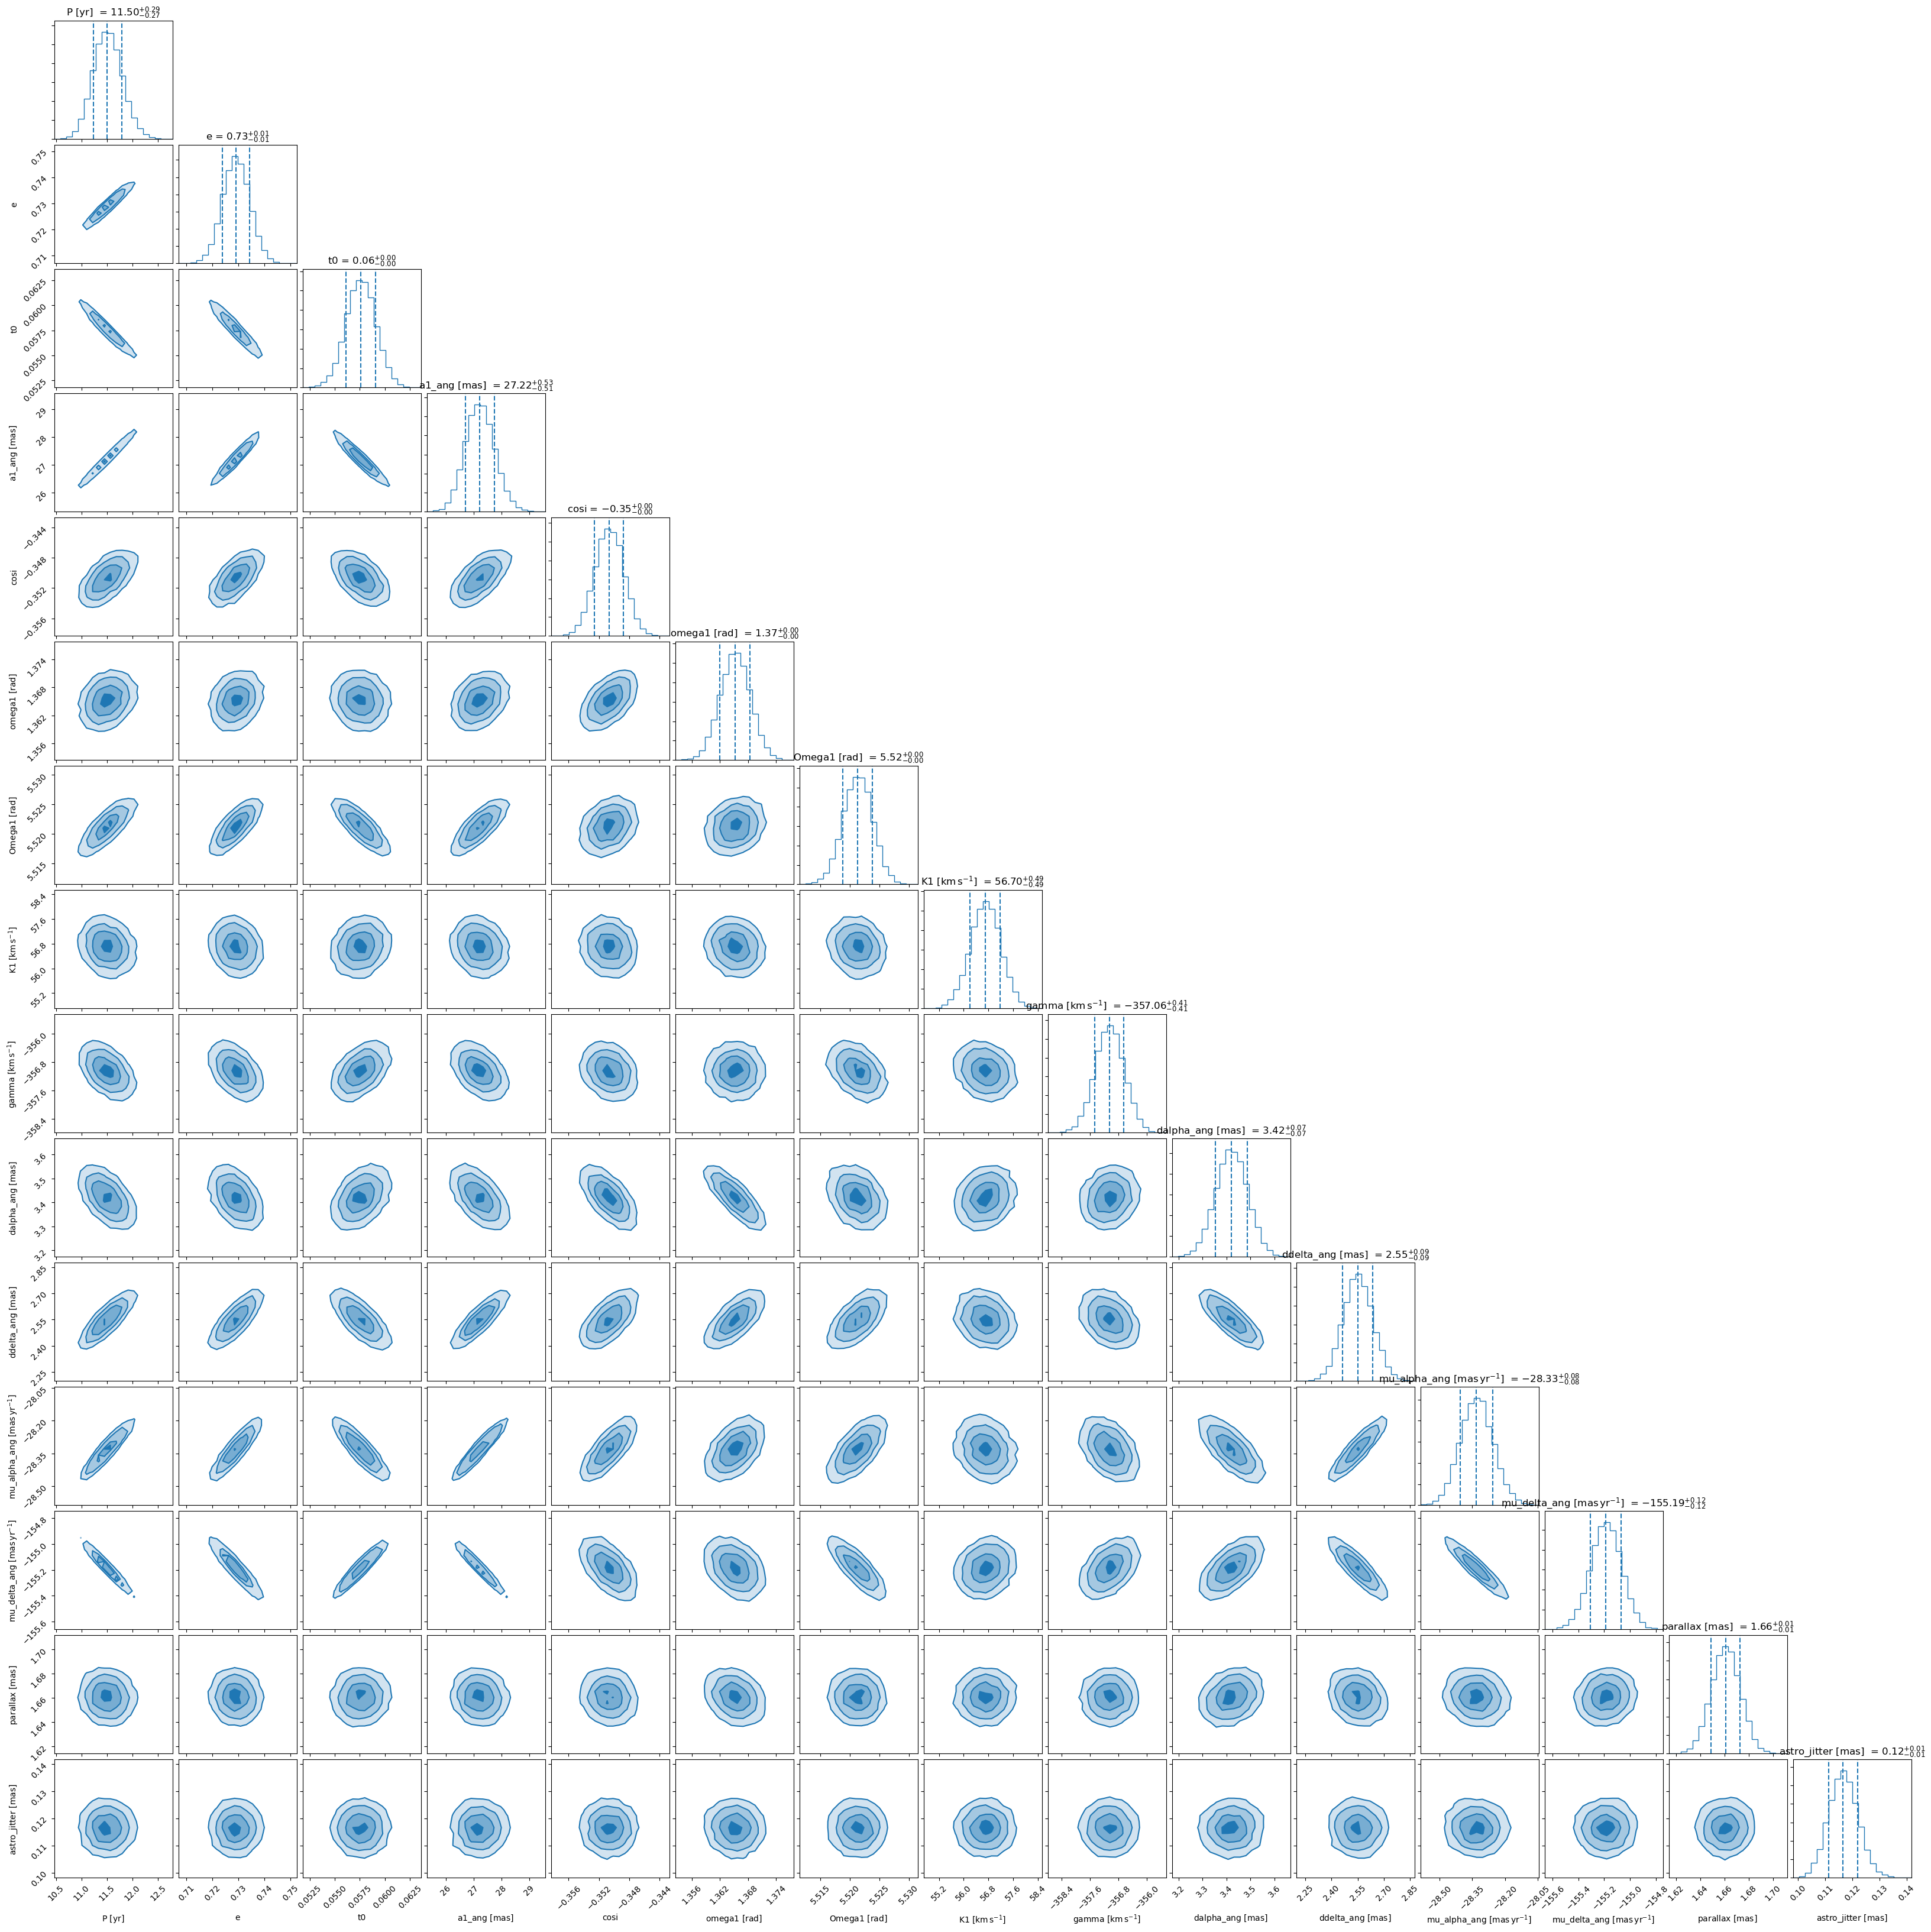

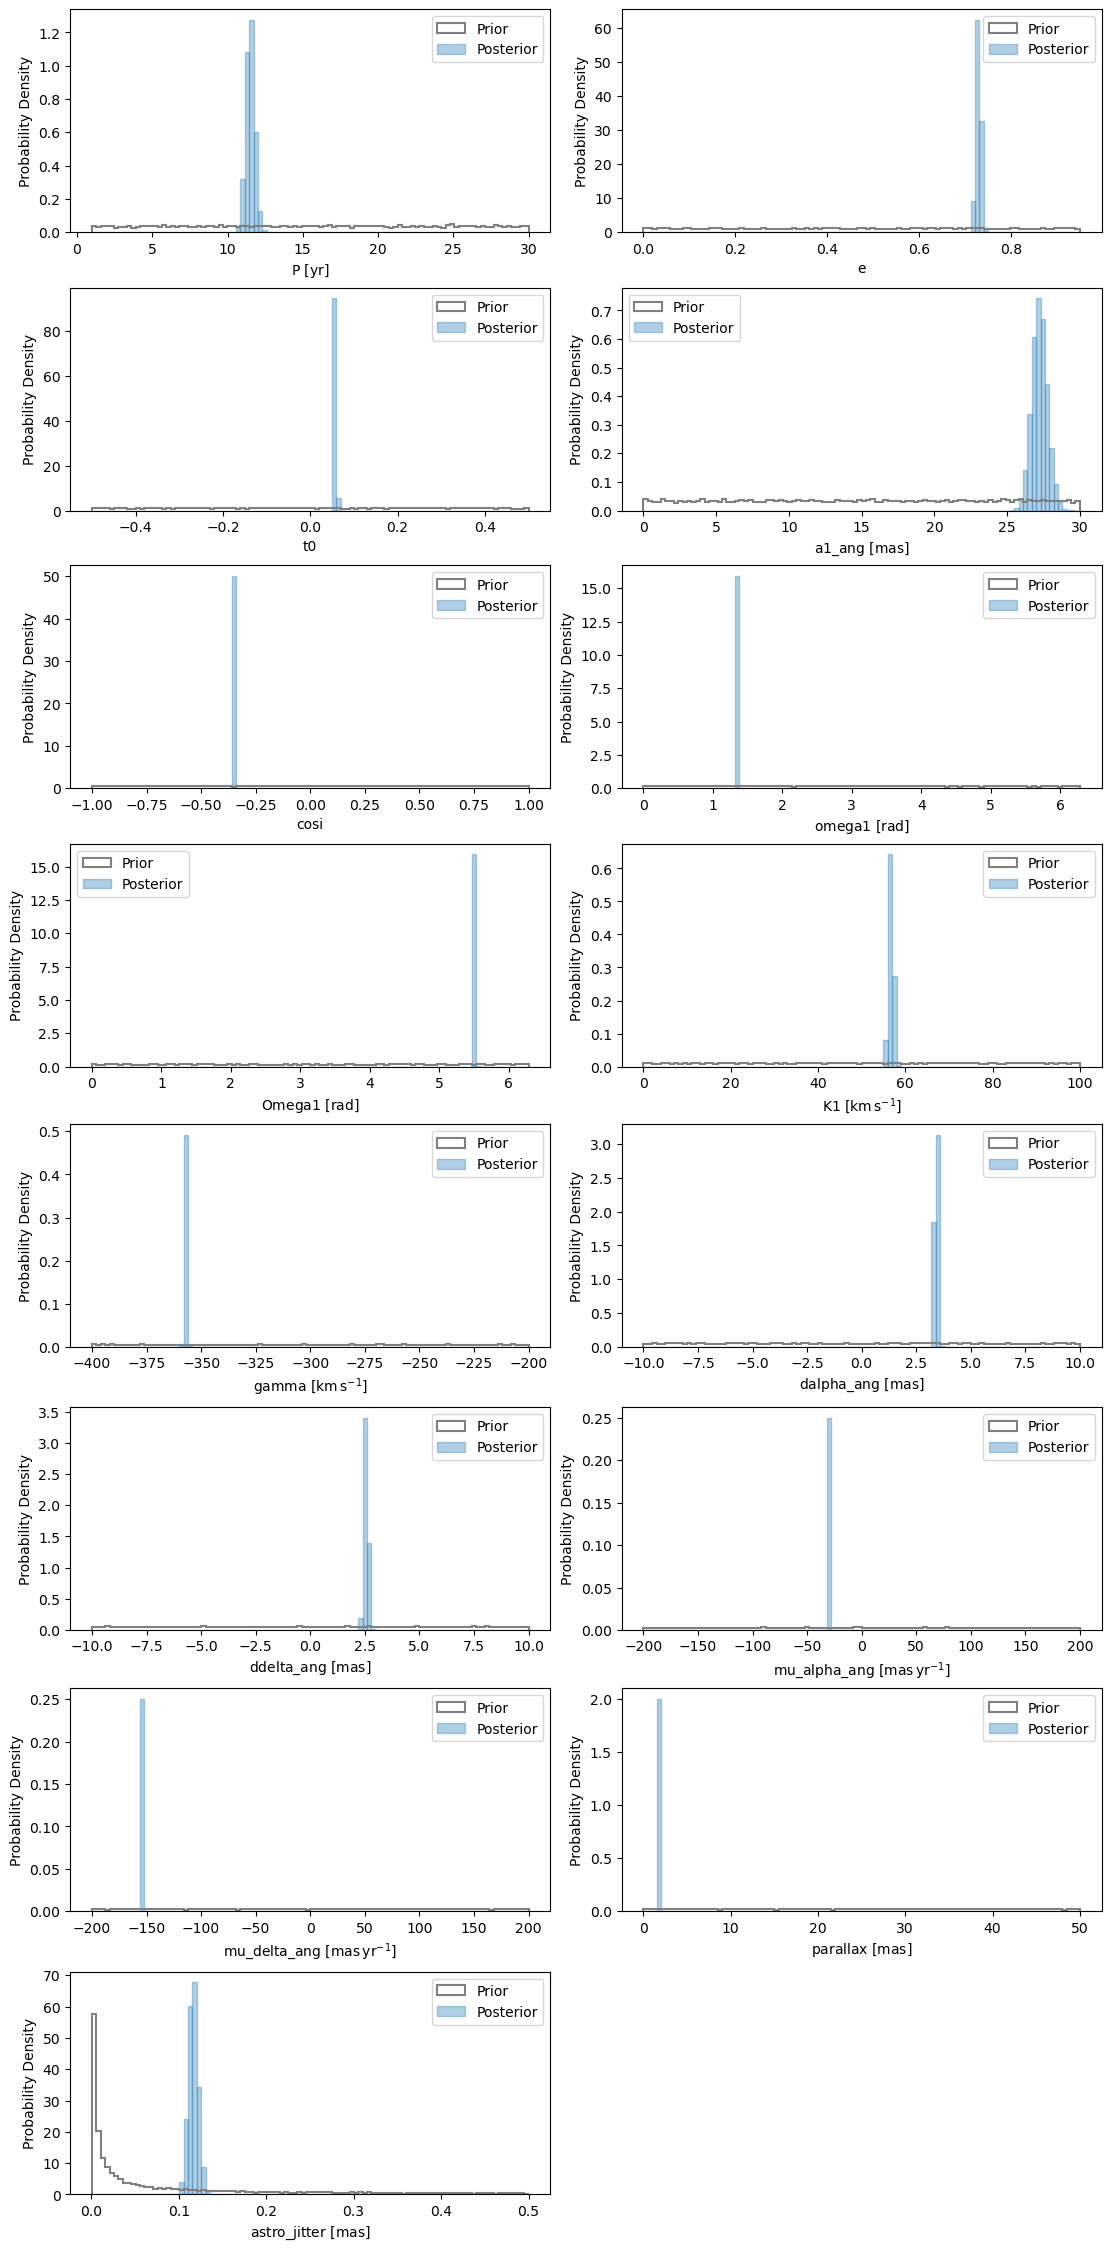

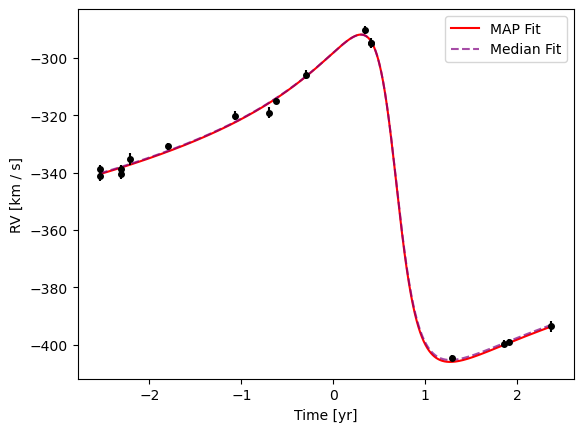

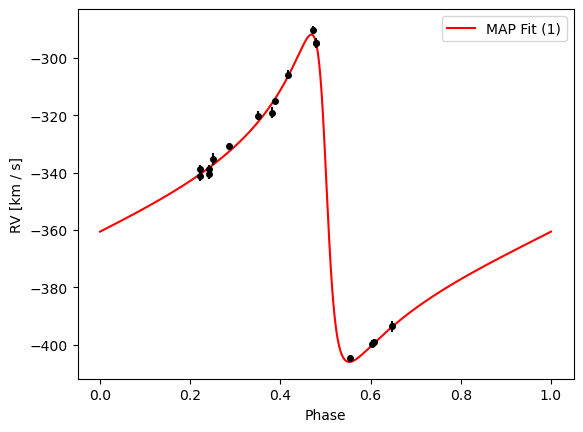

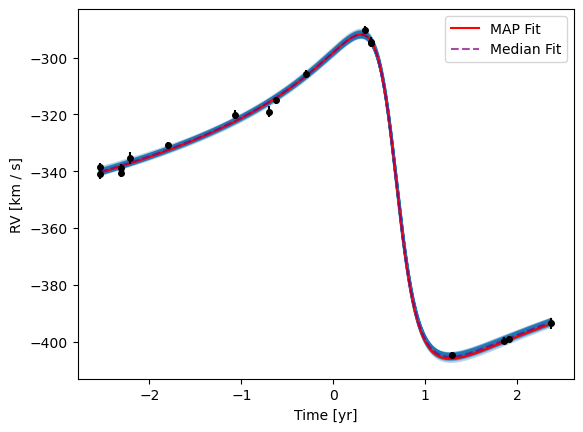

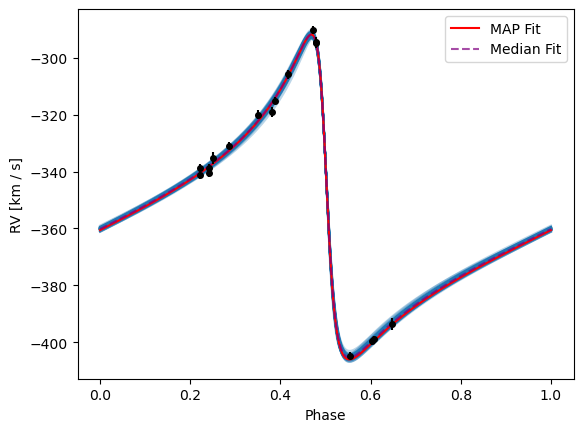

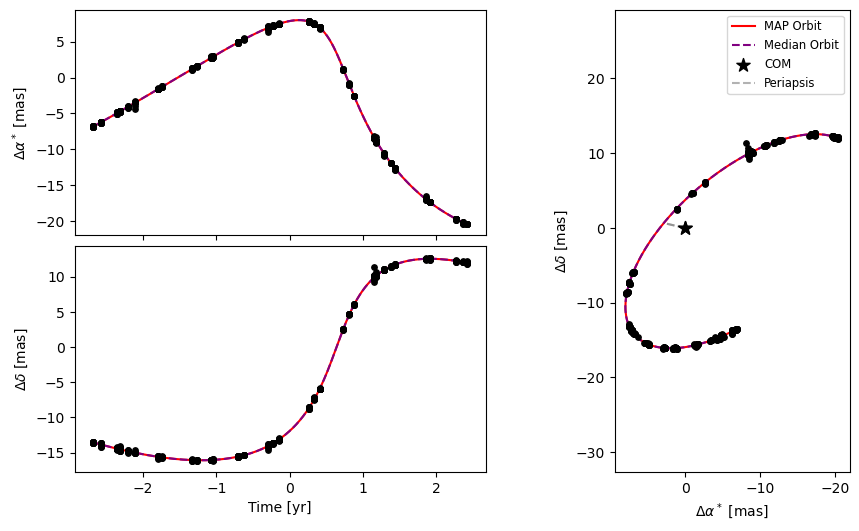

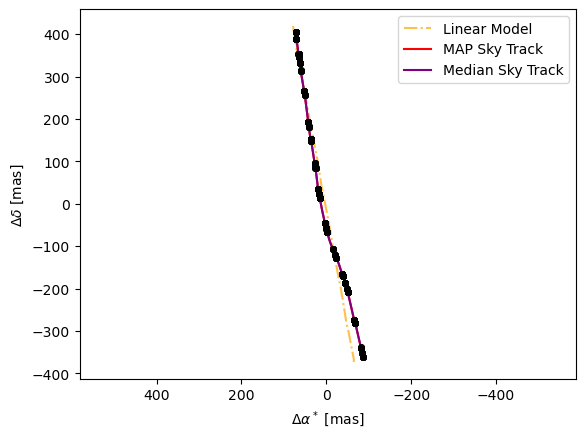

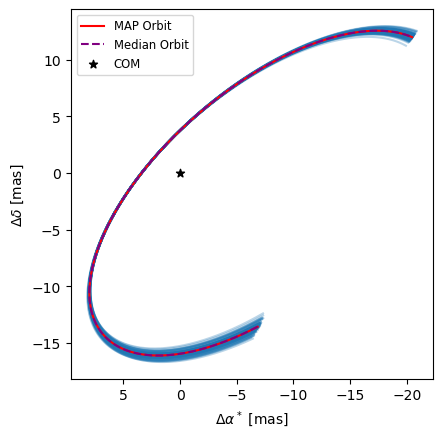

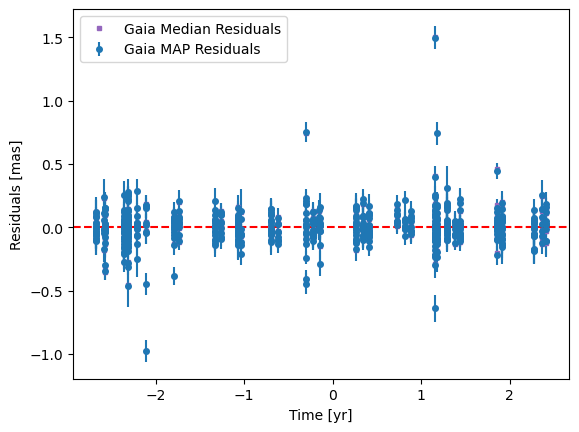

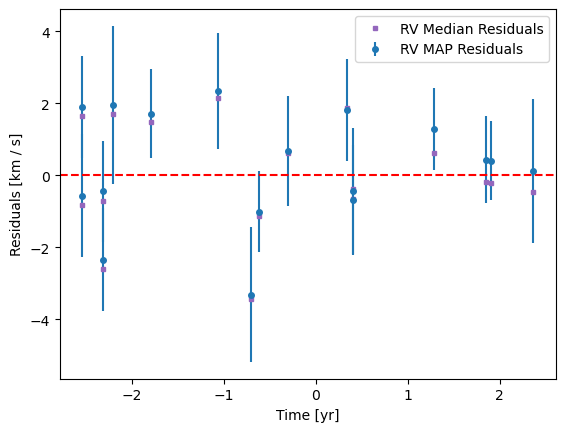

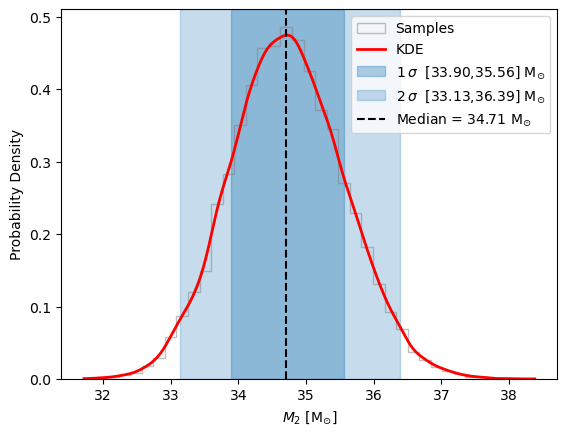

In [22]:
p.all_plots(results_full,joint)